# Traits, values and civic action: analysis notebook

This notebook contains the full analysis for the Capstone project survey, which asked whether personality traits and values predict the kinds of civic action people prefer to take. It uses survey responses from 310 UK adults to test three hypotheses (H1–H3, below), with exploratory analyses of barriers and the value–action gap. All analyses were run in Python, and the results are reported in section 2.4 of the accompanying report.

**Repository.** `[https://github.com/MollieKH/Capstone_survey_analysis.git]`

**How the sections map to the hypotheses.**

| | Hypothesis | Section | Stability check |
| --- | --- | --- | --- |
| **H1** | Traits and values predict which civic actions people are willing to take | 3 | 6.1 |
| **H2** | Civic actions form a smaller number of underlying dimensions, and traits and values predict which dimension people lean towards | 4 | 6.1, 6.2 |
| **H3** | Traits and values predict archetype resonance, and archetypes map onto the dimensions | 5 | 6.3 |

Section 6 checks whether the findings hold within each recruitment route. It is a robustness check, not a hypothesis test.

Sections 7 (barriers), 8 (value–action gap) and 9 (recruitment channel profile) fall outside H1–H3. They were run as exploratory extensions, discussed in the application chapter rather than the results section, and can be omitted without affecting H1–H3.

## 0. Setup

The core libraries, two display settings so wide tables aren't cut off, and the figure style.

In [1]:
import warnings
# Hide routine library warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Show up to 100 rows and every column
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', None)

The figure style: heuman brand colours and shared plotting settings, used by every figure below. Figures display at high resolution, so they can be saved by right-clicking.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# heuman brand colours
AZURE  = '#047f92'   # vivid azure
TEAL   = '#0795AB'   # lighter teal
ORANGE = '#f66c1d'
NAVY   = '#003D66'

INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e4e3df'

# Diverging scale for correlations and loadings: orange for negative, blue for positive
DIVERGING = LinearSegmentedColormap.from_list(
    'heuman', [(0, ORANGE), (0.5, '#f5f4f1'), (0.75, TEAL), (1, NAVY)])

plt.rcParams.update({
    # Brand colours as the default for any plot that doesn't set its own
    'axes.prop_cycle': cycler(color=[AZURE, ORANGE, NAVY, TEAL]),
    'figure.dpi': 120, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2,
})


def fmt(x):
    # Correlation style: '+.32' and '−.15', no leading zero
    return f'{x:+.2f}'.replace('0.', '.').replace('-', '−')

## 1. Data

The cleaned dataset is 310 responses across 102 columns.

In [3]:
csr = pd.read_csv("Capstone Survey Responses.csv")
csr.shape

(310, 102)

Repair column names (the .csv file was exported from Numbers so dashes and non-breaking spaces were misread)

In [4]:
def repair_name(s):
    """Reverse one round of UTF-8-read-as-Mac-Roman. Returns the name unchanged if it
    is already correct, so the function is safe to apply more than once."""
    try:
        return s.encode('mac_roman').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s


def repair_fully(s, limit=5):
    for _ in range(limit):
        nxt = repair_name(s)
        if nxt == s:
            return s
        s = nxt
    return s


before = list(csr.columns)
csr.columns = [repair_fully(c) for c in csr.columns]

changed = sum(a != b for a, b in zip(before, csr.columns))
print(f'{changed} of {len(csr.columns)} column names repaired')
for a, b in zip(before, csr.columns):
    if a != b:
        print(f'  {a.strip()!r}\n   -> {b.strip()!r}')

6 of 102 column names repaired
  'WILL Using your skills to support a cause (pro bono¬†expertise)'
   -> 'WILL Using your skills to support a cause (pro bono\xa0expertise)'
  'WILL Caring for and supporting people ‚Äî personally or professionally'
   -> 'WILL Caring for and supporting people — personally or professionally'
  'WILL Bringing people together ‚Äî through community-building, mediation or facilitation that creates impact'
   -> 'WILL Bringing people together — through community-building, mediation or facilitation that creates impact'
  'WILL Being intentional about where you spend your money (e.g. shopping local, independent,¬†buycotting)'
   -> 'WILL Being intentional about where you spend your money (e.g. shopping local, independent,\xa0buycotting)'
  'WILL Being conscious of your consumption ‚Äî food, fashion, energy'
   -> 'WILL Being conscious of your consumption — food, fashion, energy'
  "BARR None ‚Äì I'm happy with how active I am in civic/ community life"
   -> "BA

Check for missing values. Only the optional free-text fields and the response-source field should appear.

In [5]:
missing = csr.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

BARR Other (text)         279
ARC Other label (text)    274
Source                     13
dtype: int64

Define the variable groups used throughout: 15 traits, 6 archetypes, 7 cause categories, 17 willingness items and 7 barriers.

For brevity, "traits" refers to all 15 - the 5 personality traits and the 10 values.

`actions` and `barriers` are read from the column names rather than typed out to minimise errors.

In [6]:
# 15 traits: 5 personality (BFI) and 10 centred Schwartz values (VALCEN)
traits = ['BFI Extraversion', 'BFI Agreeableness', 'BFI Conscientiousness',
          'BFI Negative Emotionality', 'BFI Open-Mindedness',
          'VALCEN Conformity', 'VALCEN Tradition', 'VALCEN Benevolence',
          'VALCEN Universalism', 'VALCEN Self-Direction', 'VALCEN Stimulation',
          'VALCEN Hedonism', 'VALCEN Achievement', 'VALCEN Power', 'VALCEN Security']

archetypes = ['ARC Caregiver', 'ARC Advocate', 'ARC Connector',
              'ARC Steward', 'ARC Challenger', 'ARC Catalyst']

causes = ['CAT Health', 'CAT Wellbeing', 'CAT Justice', 'CAT Planet',
          'CAT Animals', 'CAT Humanitarian', 'CAT Future']

# Read 17 willingness items from the column names
actions = [c for c in csr.columns if c.startswith('WILL')]
# The 7 tick-box barriers, leaving out the free-text 'Other' column
barriers = [c for c in csr.columns if c.startswith('BARR') and 'text' not in c]

print(len(traits), len(archetypes), len(causes), len(actions), len(barriers))

15 6 7 17 7


### 1.1 Recruitment route

Responses came through two routes: a Microsoft Forms link distributed directly, and the SurveySwap participant-exchange platform. The two are distinguished by the response ID prefix (`MS` or `SS`). 222 responses came through Microsoft Forms (71.6%) and 88 through SurveySwap (28.4%).

In [7]:
csr['recruitment'] = (csr['Response ID'].astype(str).str[:2].str.lower()
                      .map({'ms': 'Microsoft Forms', 'ss': 'SurveySwap'}))

route = csr['recruitment'].value_counts(dropna=False)
display(pd.DataFrame({'n': route, '%': (route / len(csr) * 100).round(1)}))

,n,%
recruitment,,
Microsoft Forms,222,71.6
SurveySwap,88,28.4


### 1.2 Demographic profile

Counts and percentages for each demographic variable.

One respondent selected "Option 2" in the age question — a placeholder mistakenly left in the form rather than a real category. Reviewing the form and the order of its options established that selecting it withheld an answer rather than recording one, so the response is recoded as a declined answer.

In [8]:
csr['DEM Age'] = csr['DEM Age'].replace('Option 2', 'Prefer not to say')

demographics = ['DEM Age', 'DEM Gender identity', 'DEM Ethnicity',
                'DEM Education', 'DEM Financial situation']

rows = []
for col in demographics:
    counts = csr[col].value_counts()
    for category, n in counts.items():
        rows.append({'Variable': col.replace('DEM ', ''),
                     'Category': category,
                     'n': n,
                     '%': round(n / len(csr) * 100, 1)})

demographic_table = pd.DataFrame(rows)
demographic_table

,Variable,Category,n,%
0,Age,25 to 34,75,24.2
1,Age,18 to 24,67,21.6
2,Age,35 to 44,51,16.5
3,Age,55 to 64,45,14.5
4,Age,45 to 54,39,12.6
5,Age,65 to 74,26,8.4
6,Age,75 to 84,5,1.6
7,Age,Prefer not to say,2,0.6
8,Gender identity,Woman,196,63.2
9,Gender identity,Man,94,30.3


### 1.3 Demographics by recruitment route

Whether the two routes recruited comparable people. No significance test is run as several of these variables have categories too small for a chi-square test (expected counts below 5). The question that bears on the results is whether the two routes differ on the *analysis* variables - this is addressed in section 6.

In [9]:
split_rows = []
for col in demographics:
    ct = pd.crosstab(csr[col].fillna('Not stated'), csr['recruitment'])
    ct['Total'] = ct.sum(axis=1)
    for category, counts in ct.iterrows():
        row = {'Variable': col.replace('DEM ', ''), 'Category': category}
        for group in ct.columns:
            row[f'{group} n'] = counts[group]
            # Percentage within each route (or of all 310 for Total)
            row[f'{group} %'] = round(counts[group] / ct[group].sum() * 100, 1)
        split_rows.append(row)

demographics_by_route = pd.DataFrame(split_rows)
demographics_by_route

,Variable,Category,Microsoft Forms n,Microsoft Forms %,SurveySwap n,SurveySwap %,Total n,Total %
0,Age,18 to 24,17,7.7,50,56.8,67,21.6
1,Age,25 to 34,52,23.4,23,26.1,75,24.2
2,Age,35 to 44,43,19.4,8,9.1,51,16.5
3,Age,45 to 54,33,14.9,6,6.8,39,12.6
4,Age,55 to 64,45,20.3,0,0.0,45,14.5
5,Age,65 to 74,26,11.7,0,0.0,26,8.4
6,Age,75 to 84,5,2.3,0,0.0,5,1.6
7,Age,Prefer not to say,1,0.5,1,1.1,2,0.6
8,Gender identity,Genderqueer / another identity,4,1.8,0,0.0,4,1.3
9,Gender identity,Man,57,25.7,37,42.0,94,30.3


### 1.4 Sample size and detectable effects

The smallest correlation detectable at 80% power is .16 in the full sample, so a null means no association of that size or larger rather than no association at all. In the SurveySwap subsample it is .29, which is why section 6 compares direction rather than significance.

Both analyses with sample-size requirements are comfortable: 18:1 cases per item for the factor analysis against a conventional minimum of 5:1, and 22:1 cases per predictor for the regression against Green's (1991) N ≥ 50 + 8m = 162.

In [10]:
from scipy import stats


def min_detectable_r(n, alpha=0.05, power=0.80):
    """Smallest correlation this n could detect, via the Fisher z approximation."""
    target = stats.norm.ppf(power) + stats.norm.ppf(1 - alpha / 2)
    return np.tanh(target / np.sqrt(n - 3))


n_ms = int((csr['recruitment'] == 'Microsoft Forms').sum())
for label, n in [('full sample', len(csr)), ('Microsoft route', n_ms),
                 ('SurveySwap route', len(csr) - n_ms)]:
    print(f'{label:<17} n = {n:>3}   smallest r at 80% power = {min_detectable_r(n):.2f}')

print(f'\nFactor analysis (section 4): {len(csr)} cases / {len(actions)} items = '
      f'{len(csr) / len(actions):.1f} : 1')
# 14 rather than 15 predictors: the ten centred values sum to zero for each person,
# so one is dropped as a reference for the model to be estimable (see 5.4)
print(f'Regression (section 5.4):    {len(csr)} cases / {len(traits) - 1} predictors = '
      f'{len(csr) / (len(traits) - 1):.1f} : 1')

full sample       n = 310   smallest r at 80% power = 0.16
Microsoft route   n = 222   smallest r at 80% power = 0.19
SurveySwap route  n =  88   smallest r at 80% power = 0.29

Factor analysis (section 4): 310 cases / 17 items = 18.2 : 1
Regression (section 5.4):    310 cases / 14 predictors = 22.1 : 1


## 2. Descriptive statistics

The 42 score variables: 5 personality traits, 10 values in both raw and centred form, 6 archetype ratings, 7 cause proportions, total causes ticked, and the 3 VLQ variables.

Normality is not tested. Spearman works on the ranks of the data rather than the values, so it makes no assumption about their distribution. It is used because these variables are ordinal, bounded or discrete, and the question throughout is whether two variables rise and fall together (monotonic association). The regression in 5.4 does assume normally distributed residuals, but at n = 310 its F tests are robust to non-normal residuals.

In [11]:
# The 42: causes, VLQ, personality traits, raw values, centred values, archetypes.
# The raw value columns are named 'VAL' in place of 'VALCEN'
key_vars = (causes + ['CAUSE total', 'VLQ Importance', 'VLQ Action', 'VLQ C-B Gap']
            + traits[:5]
            + [t.replace('VALCEN', 'VAL') for t in traits[5:]]
            + traits[5:]
            + archetypes)

print(len(key_vars))
# flip table so each variable is a row
csr[key_vars].describe().T.round(3)

42


,count,mean,std,min,25%,50%,75%,max
CAT Health,310.0,0.499,0.352,0.00,0.330,0.330,0.670,1.00
CAT Wellbeing,310.0,0.414,0.309,0.00,0.200,0.400,0.600,1.00
CAT Justice,310.0,0.330,0.313,0.00,0.000,0.200,0.600,1.00
CAT Planet,310.0,0.369,0.367,0.00,0.000,0.250,0.750,1.00
CAT Animals,310.0,0.296,0.366,0.00,0.000,0.000,0.670,1.00
CAT Humanitarian,310.0,0.281,0.373,0.00,0.000,0.000,0.670,1.00
CAT Future,310.0,0.298,0.329,0.00,0.000,0.330,0.585,1.00
CAUSE total,310.0,9.319,6.490,1.00,5.000,8.000,12.000,26.00
VLQ Importance,310.0,7.571,1.878,1.00,7.000,8.000,9.000,10.00
VLQ Action,310.0,5.855,2.426,1.00,4.000,6.000,8.000,10.00


## 3. H1 — Do traits predict which actions people are willing to take?

*The baseline correlations for all six blocks are computed here at once, so they share one FDR correction. The trait–action block is the evidence for H1.*

### 3.1 All variable pairs

Every trait, archetype, action and cause category correlated against each other in six blocks, then FDR-corrected across all 713 at once.

Of the 713 pairs, 403 survive FDR correction, 177 of them in Traits–Actions.

Because each person’s ten centred values sum to zero, a positive association for one value forces a negative association with at least one other, so correlations involving centred values describe relative priority (which values someone holds above their own average).

In [12]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# Correlate every variable in one group with every variable in another
def correlate_blocks(group1, group2, df):
    rows = []
    for var1 in group1:
        for var2 in group2:
            rho, p = spearmanr(df[var1], df[var2])
            rows.append({'Var1': var1, 'Var2': var2, 'rho': rho, 'p': p})
    return pd.DataFrame(rows)

# The first three blocks are primary; the three involving causes are supplementary
blocks = {
    'Traits-Actions':     (traits, actions),
    'Traits-Archetypes':  (traits, archetypes),
    'Archetypes-Actions': (archetypes, actions),
    'Traits-Causes':      (traits, causes),
    'Causes-Archetypes':  (causes, archetypes),
    'Causes-Actions':     (causes, actions),
}

# Run all six blocks and stack them into one table
all_correlations = pd.concat(
    [correlate_blocks(g1, g2, csr).assign(Block=name) for name, (g1, g2) in blocks.items()],
    ignore_index=True
)
# FDR correction across all 713 at once
# multipletests returns four items; [1] picks out adjusted p-values
all_correlations['q'] = multipletests(all_correlations['p'], method='fdr_bh')[1]

n_sig = (all_correlations['q'] < 0.05).sum()
print(f"{n_sig} of {len(all_correlations)} significant after FDR ({n_sig/len(all_correlations)*100:.1f}%)")
all_correlations[all_correlations['q'] < 0.05]['Block'].value_counts()

403 of 713 significant after FDR (56.5%)


Block
Traits-Actions        177
Archetypes-Actions     78
Causes-Actions         63
Traits-Archetypes      39
Traits-Causes          35
Causes-Archetypes      11
Name: count, dtype: int64

### 3.2 Robustness check — raw values against centred values

A check on the scoring decision described in the methods. The same correlations are run twice for each of the 10 Schwartz values — once with raw scores, once with centred scores — against all 17 actions and 6 archetypes. Each set is FDR-corrected separately (230 tests each).

Rank agreement between the two sets of rho values is .964, the mean absolute difference .070, and 18 pairs change sign. 138 of 230 survive FDR on raw scores against 163 on centred.

The two versions tell the same story, but centring sharpens it. Raw scoring shifts every value's correlations upwards. The table below gives the mean absolute difference per value, which runs from .04 to .09. This is a general endorsement effect: people who rate all values highly also report more willingness. Removing it clarifies the values that relate *negatively* to engagement: Security rises from 3 significant associations to 13, Achievement from 9 to 18, Conformity from 7 to 16. Hedonism moves the other way, 15 to 5. The 18 sign flips cluster in Security and Conformity, whose raw correlations sat near zero.

In [13]:
values_centred = [t for t in traits if t.startswith('VALCEN')]
# Matching raw columns
values_raw = [v.replace('VALCEN', 'VAL') for v in values_centred]
outcomes = actions + archetypes

val_rows = []
# For each value, correlate both versions with the same outcome so they sit side by side
for raw, cen in zip(values_raw, values_centred):
    for out in outcomes:
        rho_r, p_r = spearmanr(csr[raw], csr[out])
        rho_c, p_c = spearmanr(csr[cen], csr[out])
        val_rows.append({'value': cen.replace('VALCEN ', ''), 'outcome': out.strip(),
                         'rho_raw': rho_r, 'p_raw': p_r,
                         'rho_centred': rho_c, 'p_centred': p_c})

val_check = pd.DataFrame(val_rows)
# Correct each set separately, so neither is penalised for the other's tests
val_check['q_raw'] = multipletests(val_check['p_raw'], method='fdr_bh')[1]
val_check['q_centred'] = multipletests(val_check['p_centred'], method='fdr_bh')[1]
val_check['abs_diff'] = (val_check['rho_raw'] - val_check['rho_centred']).abs()
# True where raw and centred point in opposite directions
val_check['sign_flip'] = np.sign(val_check['rho_raw']) != np.sign(val_check['rho_centred'])

sig_raw = (val_check['q_raw'] < 0.05).sum()
sig_cen = (val_check['q_centred'] < 0.05).sum()
# How closely the two sets of rho values track each other overall (1 = identical ranking)
agreement, _ = spearmanr(val_check['rho_raw'], val_check['rho_centred'])

print(f"Significant after FDR:  raw {sig_raw} of {len(val_check)},  centred {sig_cen} of {len(val_check)}")
print(f"Agreement between the two sets of rho values: {agreement:.3f}")
print(f"Mean absolute difference in rho: {val_check['abs_diff'].mean():.3f}")
print(f"Pairs where the sign flips: {val_check['sign_flip'].sum()}")

Significant after FDR:  raw 138 of 230,  centred 163 of 230
Agreement between the two sets of rho values: 0.964
Mean absolute difference in rho: 0.070
Pairs where the sign flips: 18


The same comparison broken down by value in order of most affected by centring.

In [14]:
val_check.groupby('value').agg(
    mean_rho_raw=('rho_raw', 'mean'),
    mean_rho_centred=('rho_centred', 'mean'),
    mean_abs_diff=('abs_diff', 'mean'),
    sig_raw=('q_raw', lambda x: (x < 0.05).sum()),
    sig_centred=('q_centred', lambda x: (x < 0.05).sum()),
    sign_flips=('sign_flip', 'sum')
).sort_values('mean_abs_diff', ascending=False).round(3)

,mean_rho_raw,mean_rho_centred,mean_abs_diff,sig_raw,sig_centred,sign_flips
value,,,,,,
Security,-0.034,-0.125,0.093,3,13,5
Achievement,-0.075,-0.159,0.084,9,18,1
Power,-0.025,-0.108,0.084,7,15,2
Tradition,-0.172,-0.252,0.083,16,19,2
Conformity,-0.082,-0.162,0.080,7,16,3
Hedonism,0.136,0.078,0.066,15,5,2
Universalism,0.308,0.255,0.063,21,20,1
Benevolence,0.295,0.255,0.058,20,19,1
Self-Direction,0.260,0.246,0.044,22,20,0


### 3.3 Breadth — which traits relate to action widely, and which narrowly

For each trait: how many of the 17 actions it correlates with at q < .05, and how strongly on average.

Six traits reach all 17 actions — Universalism, Benevolence, Tradition, Open-Mindedness, Self-Direction and Agreeableness — at mean |rho| between .22 and .32. The narrowest are Conscientiousness (1 action) and Hedonism (4). 14 of the 15 traits are listed as Negative Emotionality has no significant action correlations so does not appear in the table.

Descriptive only: no predictors are selected from this anywhere, and the model in 5.4 enters all traits.

In [15]:
# Keep only Traits–Actions pairs that survived FDR
trait_action_sig = all_correlations[
    (all_correlations['Block'] == 'Traits-Actions') & (all_correlations['q'] < 0.05)
]

# For each trait: how many actions it reaches, and how strongly on average
# Includes negative correlations as strength
trait_breadth = trait_action_sig.groupby('Var1').agg(
    n_significant_actions=('Var2', 'count'),
    mean_rho=('rho', 'mean'),
    mean_abs_rho=('rho', lambda x: x.abs().mean()),
    min_rho=('rho', 'min'),
    max_rho=('rho', 'max')
).sort_values('mean_abs_rho', ascending=False)

trait_breadth.round(3)

,n_significant_actions,mean_rho,mean_abs_rho,min_rho,max_rho
Var1,,,,,
VALCEN Universalism,17,0.315,0.315,0.216,0.408
VALCEN Benevolence,17,0.311,0.311,0.212,0.418
VALCEN Tradition,17,-0.301,0.301,-0.421,-0.223
BFI Open-Mindedness,17,0.297,0.297,0.145,0.428
VALCEN Self-Direction,17,0.271,0.271,0.199,0.410
BFI Agreeableness,17,0.221,0.221,0.136,0.279
VALCEN Conformity,11,-0.198,0.198,-0.317,-0.125
BFI Extraversion,10,0.191,0.191,0.139,0.312
VALCEN Achievement,15,-0.190,0.190,-0.257,-0.125


### 3.4 Overall willingness against traits

The mean of all 17 willingness items, correlated with each trait. This is the general engagement pattern.

Six traits correlate at .30 or above, moderate by Cohen's (1988) convention. These are the same six traits that correlate with all 17 actions individually, reinforcing these as markers of general engagement. Negative Emotionality and Conscientiousness are not significant.

In [16]:
csr['WILL_mean'] = csr[actions].mean(axis=1)

# Each person's average across the 17 willingness items
will_mean_rows = []
for trait in traits:
    rho, p = spearmanr(csr[trait], csr['WILL_mean'])
    will_mean_rows.append({'trait': trait, 'rho': rho, 'p': p})

will_mean_df = pd.DataFrame(will_mean_rows)
will_mean_df['q'] = multipletests(will_mean_df['p'], method='fdr_bh')[1]
will_mean_df.sort_values('rho', key=abs, ascending=False).round(4)

,trait,rho,p,q
8,VALCEN Universalism,0.4560,0.0000,0.0000
7,VALCEN Benevolence,0.4419,0.0000,0.0000
6,VALCEN Tradition,-0.4307,0.0000,0.0000
4,BFI Open-Mindedness,0.3951,0.0000,0.0000
9,VALCEN Self-Direction,0.3724,0.0000,0.0000
1,BFI Agreeableness,0.3065,0.0000,0.0000
5,VALCEN Conformity,-0.2685,0.0000,0.0000
12,VALCEN Achievement,-0.2602,0.0000,0.0000
10,VALCEN Stimulation,0.2314,0.0000,0.0001
14,VALCEN Security,-0.2072,0.0002,0.0004


### 3.5 Willingness, cause breadth and importance

Is engagement one thing? Three measures of "how much" someone engages, correlated with each other: overall willingness, number of causes ticked (out of the full 26 across the 7 categories), and how important civic action is to them (VLQ Importance).

Willingness–importance is .492, willingness–causes .307, and causes–importance .223 (all p < .001). Willingness and importance are most closely related; cause breadth is moderately related to willingness and only weakly to importance. The three are related but not interchangeable as measures of engagement.

In [17]:
# The three pairwise correlations between the three 'how much' measures
for a, b in [('WILL_mean', 'CAUSE total'), ('WILL_mean', 'VLQ Importance'), ('CAUSE total', 'VLQ Importance')]:
    rho, p = spearmanr(csr[a], csr[b])
    print(f"{a} vs {b}: rho = {rho:.3f}, p = {p:.4f}")

WILL_mean vs CAUSE total: rho = 0.307, p = 0.0000
WILL_mean vs VLQ Importance: rho = 0.492, p = 0.0000
CAUSE total vs VLQ Importance: rho = 0.223, p = 0.0001


#### Cause-breadth prediction

People with low willingness will on average tick fewer causes, while people with higher willingness could tick any number (a high-willingness person ticking few causes signals strong but narrow interest, one ticking many signals broader interest).

This prediction was made before the data were examined, and is the only directional hypothesis in the project. People are split into thirds by overall willingness. Levene’s test checks whether people in the lowest third differ less from each other in how many causes they tick than everyone else does.

The lowest third ticks fewer causes on average (7.11, against 9.86 and 11.38), and differs less in how many: Levene’s W = 4.39, p = .037, SD 5.43 against 6.72 for the rest.

In [18]:
from scipy.stats import levene

# Split people into three groups of approximately equal size by overall willingness.
# Ties mean the groups come out at 116 / 95 / 99 rather than exactly equal.
csr['will_tertile'] = pd.qcut(csr['WILL_mean'], 3, labels=['Low', 'Mid', 'High'])
display(csr.groupby('will_tertile')['CAUSE total'].agg(['mean', 'std', 'min', 'max', 'count']).round(2))

# Causes ticked by the lowest third, and by everyone else
low = csr.loc[csr['will_tertile'] == 'Low', 'CAUSE total']
rest = csr.loc[csr['will_tertile'] != 'Low', 'CAUSE total']
# Levene's test compares spread (variance), not averages
stat, p = levene(low, rest)
print(f"Levene's test, lowest third vs rest: W = {stat:.3f}, p = {p:.4f}")
print(f"SD lowest third: {low.std():.2f},  SD rest: {rest.std():.2f}")

,mean,std,min,max,count
will_tertile,,,,,
Low,7.11,5.43,1,26,116
Mid,9.86,6.73,1,26,95
High,11.38,6.66,1,26,99


Levene's test, lowest third vs rest: W = 4.389, p = 0.0370
SD lowest third: 5.43,  SD rest: 6.72


In [19]:
# EXTRA, exploratory: cause breadth = how many of the 7 categories have at least one cause ticked (0–7).
# Self-contained: delete this cell to remove it.
breadth = (csr[causes] > 0).sum(axis=1)
print(breadth.value_counts().sort_index())
for other in ['CAUSE total', 'WILL_mean', 'VLQ Importance']:
    rho, p = spearmanr(breadth, csr[other])
    print(f"Breadth vs {other}: rho = {rho:.3f}, p = {p:.4f}")

1    32
2    20
3    49
4    50
5    57
6    51
7    51
Name: count, dtype: int64
Breadth vs CAUSE total: rho = 0.890, p = 0.0000
Breadth vs WILL_mean: rho = 0.265, p = 0.0000
Breadth vs VLQ Importance: rho = 0.199, p = 0.0004


### 3.6 Ipsatised items

Centring separates which actions someone favours from how much they are willing to do overall.

Each person's 17 ratings are centred on their own mean across those 17, so every person's scores sum to zero. Overall engagement is removed by construction - what survives is not explained by how engaged someone is.

The first output shows the sample-wide tilt — political items sit well below people's own average.

In [20]:
# Subtract each person's own average from each of their 17 ratings
will_centred = csr[actions].sub(csr[actions].mean(axis=1), axis=0)
# Add [c] to each name to mark it as centred
will_centred.columns = [c.strip() + ' [c]' for c in will_centred.columns]

will_centred.describe().T[['mean', 'std']].round(3)

,mean,std
WILL Speaking up about issues you understand and care about [c],0.211,0.819
WILL Donating money/items to organisations doing work you believe in [c],0.414,0.689
WILL Volunteering for a cause/community you care about [c],0.340,0.629
WILL Using your skills to support a cause (pro bono expertise) [c],0.440,0.589
WILL Choosing work based on the positive impact it has [c],0.489,0.647
WILL Participating in neighbourhood groups [c],-0.044,0.732
WILL Caring for and supporting people — personally or professionally [c],0.202,0.715
"WILL Bringing people together — through community-building, mediation or facilitation that creates impact [c]",0.060,0.740
WILL Voting and engaging with elections [c],0.231,0.815
WILL Signing petitions [c],0.014,0.767


Traits against the items, uncentred then centred, each FDR-corrected within the same 255.

Uncentred, 186 survive (3.1 reports 177 because it corrects across all 713 pairs). Centred, four survive at q < .05 and seven in total at q < .10. Far fewer trait–action associations survive once general engagement is removed: 186 before ipsatisation, 4 after.

In [21]:
# Uncentred trait–action pairs, corrected within their own 255, so the
# before/after comparison uses the same family on both sides
ta = all_correlations[all_correlations['Block'] == 'Traits-Actions'].copy()
ta['q_255'] = multipletests(ta['p'], method='fdr_bh')[1]
n = (ta['q_255'] < 0.05).sum()
print(f"Uncentred, corrected within the 255: {n} of {len(ta)} ({n / len(ta):.1%})")

Uncentred, corrected within the 255: 186 of 255 (72.9%)


In [22]:
# Every trait against every centred item: 15 × 17 = 255 tests
ipsative_rows = []
for trait in traits:
    for col in will_centred.columns:
        rho, p = spearmanr(csr[trait], will_centred[col])
        ipsative_rows.append({'trait': trait, 'action': col, 'rho': rho, 'p': p})

ipsative_df = pd.DataFrame(ipsative_rows)
ipsative_df['q'] = multipletests(ipsative_df['p'], method='fdr_bh')[1]

print(f"{(ipsative_df['q'] < 0.05).sum()} of {len(ipsative_df)} at q < .05")
# Show everything at q < .10, strongest first
ipsative_df[ipsative_df['q'] < 0.10].sort_values('q').round(4)

4 of 255 at q < .05


,trait,action,rho,p,q
97,VALCEN Conformity,WILL Being a member of a political party [c],-0.2427,0.0000,0.0040
98,VALCEN Conformity,WILL Campaigning and organising [c],-0.2118,0.0002,0.0219
179,VALCEN Stimulation,WILL Signing petitions [c],-0.2013,0.0004,0.0307
99,VALCEN Conformity,WILL Protesting and direct action [c],-0.1920,0.0007,0.0432
142,VALCEN Universalism,WILL Caring for and supporting people — person...,-0.1772,0.0017,0.0887
88,VALCEN Conformity,WILL Using your skills to support a cause (pro...,0.1739,0.0021,0.0892
16,BFI Extraversion,WILL Being conscious of your consumption — foo...,-0.1715,0.0024,0.0892


## 4. H2 — Do civic actions form dimensions, and do traits predict them?

### 4.1 Is the data suitable for factor analysis?

KMO is .915, above Kaiser’s (1974) .9 threshold for excellent, and Bartlett’s χ² is 3178.5, p < .001. Therefore the items are suitable for factor analysis.

In [23]:
%pip install -q --upgrade pip
%pip install -q factor_analyzer
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

# Bartlett's test: are the items correlated enough to factor at all?
chi2, p_bartlett = calculate_bartlett_sphericity(csr[actions])
# KMO: are those correlations patterned enough to reflect underlying factors?
kmo_per_item, kmo_total = calculate_kmo(csr[actions])

print(f"Bartlett's test: chi2 = {chi2:.1f}, p = {p_bartlett:.5f}")
print(f"KMO overall: {kmo_total:.3f}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Bartlett's test: chi2 = 3178.5, p = 0.00000
KMO overall: 0.915


### 4.2 How many factors?

Eigenvalues from an unrotated solution, and the scree plot.

The first three eigenvalues are 7.94, 1.93 and 1.24, dropping to .89 at the fourth. Three factors were retained on the eigenvalue structure, interpretability and the split-half replication in 4.6 — not on the eigenvalue-above-one rule alone.

The first eigenvalue, 7.94, is 47% of the total variance across the 17 items before factoring — the general engagement effect that sections 3.6 and 4.8 remove.

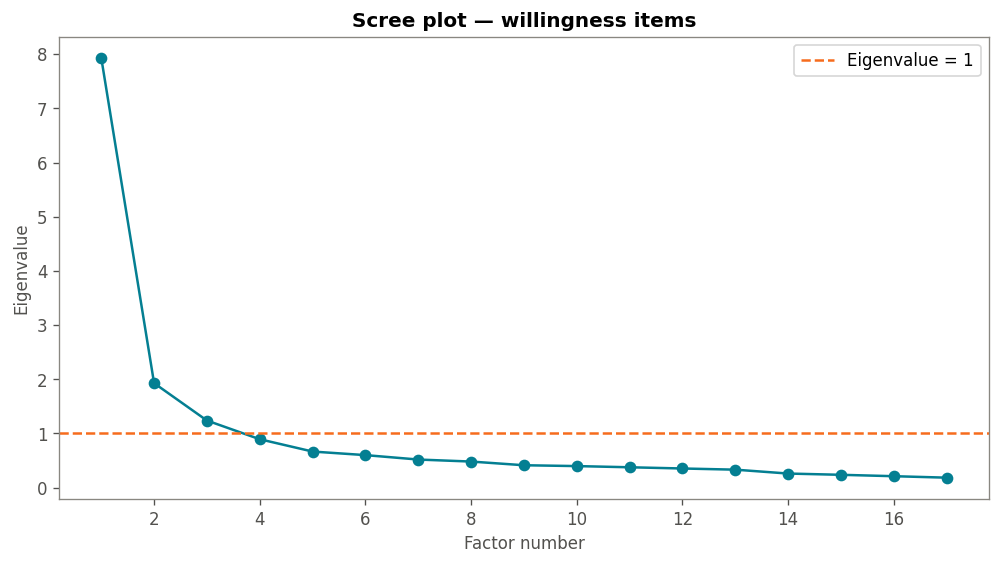

[7.935 1.927 1.237 0.892 0.664 0.599]
First factor share of variance: 46.7%


In [24]:
# As many factors as items, unrotated — only used to read off the eigenvalues
fa_check = FactorAnalyzer(n_factors=len(actions), rotation=None)
fa_check.fit(csr[actions])
eigenvalues, _ = fa_check.get_eigenvalues()

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(actions) + 1), eigenvalues, 'o-')
# Reference line at 1, the traditional cut-off
plt.axhline(y=1, color=ORANGE, linestyle='--', label='Eigenvalue = 1')
plt.xlabel('Factor number')
plt.ylabel('Eigenvalue')
plt.title('Scree plot — willingness items')
plt.legend()
plt.show()

print(eigenvalues[:6].round(3))
# An eigenvalue divided by the number of items gives that factor's share of total variance
print(f"First factor share of variance: {eigenvalues[0] / len(actions):.1%}")

### 4.3 The three-factor solution

Oblimin rotation allows the factors to correlate, which suits these data: people willing to act in one way tend to be willing to act in others.

F1 is relational, F2 political and F3 consumption, together explaining approximately 49.5% of variance (21.2% / 15.9% / 12.3%).

In [25]:
# The final solution: 3 factors, with oblimin rotation so the factors can correlate
fa = FactorAnalyzer(n_factors=3, rotation='oblimin')
fa.fit(csr[actions])

# Variance explained by each factor, individually and cumulatively
variance = pd.DataFrame(
    fa.get_factor_variance(),
    index=['SS loadings', 'Proportion var', 'Cumulative var'],
    columns=['F1', 'F2', 'F3']
).round(3)

# Loadings: how strongly each item relates to each factor
loadings = pd.DataFrame(
    fa.loadings_,
    index=[a.strip()[:45] for a in actions],
    columns=['F1', 'F2', 'F3']
).round(3)

print(variance)
print()
loadings

                   F1     F2     F3
SS loadings     3.604  2.711  2.094
Proportion var  0.212  0.159  0.123
Cumulative var  0.212  0.371  0.495



,F1,F2,F3
WILL Speaking up about issues you understand,0.550,0.089,0.079
WILL Donating money/items to organisations do,0.418,-0.092,0.494
WILL Volunteering for a cause/community you c,0.648,-0.009,0.238
WILL Using your skills to support a cause (pr,0.715,-0.002,0.139
WILL Choosing work based on the positive impa,0.602,-0.126,0.278
WILL Participating in neighbourhood groups,0.656,0.235,-0.098
WILL Caring for and supporting people — perso,0.859,-0.049,-0.073
WILL Bringing people together — through commu,0.724,0.184,-0.109
WILL Voting and engaging with elections,0.004,0.417,0.438
WILL Signing petitions,0.062,0.410,0.454


### 4.4 Building the composites

Each composite is the unweighted mean of the items that load clearly on its factor. An item loading .32 or above on more than one factor counts as cross-loading (Costello & Osborne, 2005).

Voting and signing petitions cross-load on political and consumption, so they are left out of all three composites rather than assigned arbitrarily.

Donating also cross-loads (relational .42, consumption .49) but is kept in consumption. Without it, consumption would have two items, and a factor with fewer than three items is weak and unstable (Costello & Osborne, 2005).

In [26]:
# Each factor's items from the loading pattern in 4.3
# They are matched using a distinctive phrase to minimise errors
f1_keys = ['Caring for', 'Bringing people', 'Using your skills', 'neighbourhood',
           'Volunteering', 'Choosing work', 'Speaking up']
f2_keys = ['Campaigning', 'political party', 'Protesting', 'consultations', 'MP or other']
f3_keys = ['intentional about where', 'conscious of your consumption', 'Donating']

f1_items = [a for a in actions if any(k in a for k in f1_keys)]
f2_items = [a for a in actions if any(k in a for k in f2_keys)]
f3_items = [a for a in actions if any(k in a for k in f3_keys)]

# Print the final membership to make analytical decision explicit in the output
for name, items in [('Relational', f1_items), ('Political', f2_items), ('Consumption', f3_items)]:
    print(f'{name} ({len(items)} items)')
    for a in items:
        print('   ', a.strip())
    print()

# Each composite is the person's average across that factor's items
csr['relational_score'] = csr[f1_items].mean(axis=1)
csr['political_score'] = csr[f2_items].mean(axis=1)
csr['consumption_score'] = csr[f3_items].mean(axis=1)

csr[['relational_score', 'political_score', 'consumption_score']].describe().round(3)

Relational (7 items)
    WILL Speaking up about issues you understand and care about
    WILL Volunteering for a cause/community you care about
    WILL Using your skills to support a cause (pro bono expertise)
    WILL Choosing work based on the positive impact it has
    WILL Participating in neighbourhood groups
    WILL Caring for and supporting people — personally or professionally
    WILL Bringing people together — through community-building, mediation or facilitation that creates impact

Political (5 items)
    WILL Responding to consultations
    WILL Writing to an MP or other representative
    WILL Being a member of a political party
    WILL Campaigning and organising
    WILL Protesting and direct action

Consumption (3 items)
    WILL Donating money/items to organisations doing work you believe in
    WILL Being intentional about where you spend your money (e.g. shopping local, independent, buycotting)
    WILL Being conscious of your consumption — food, fashion, energy



,relational_score,political_score,consumption_score
count,310.000,310.000,310.000
mean,4.231,3.415,4.297
std,0.730,0.998,0.804
min,1.000,1.000,1.000
25%,3.857,2.800,4.000
50%,4.286,3.400,4.333
75%,4.857,4.200,5.000
max,5.000,5.000,5.000


**Figure: the three dimensions of willingness.** Factor loadings from 4.3, grouped by the composite each item belongs to. Grey labels indicate the items left out of the composites.

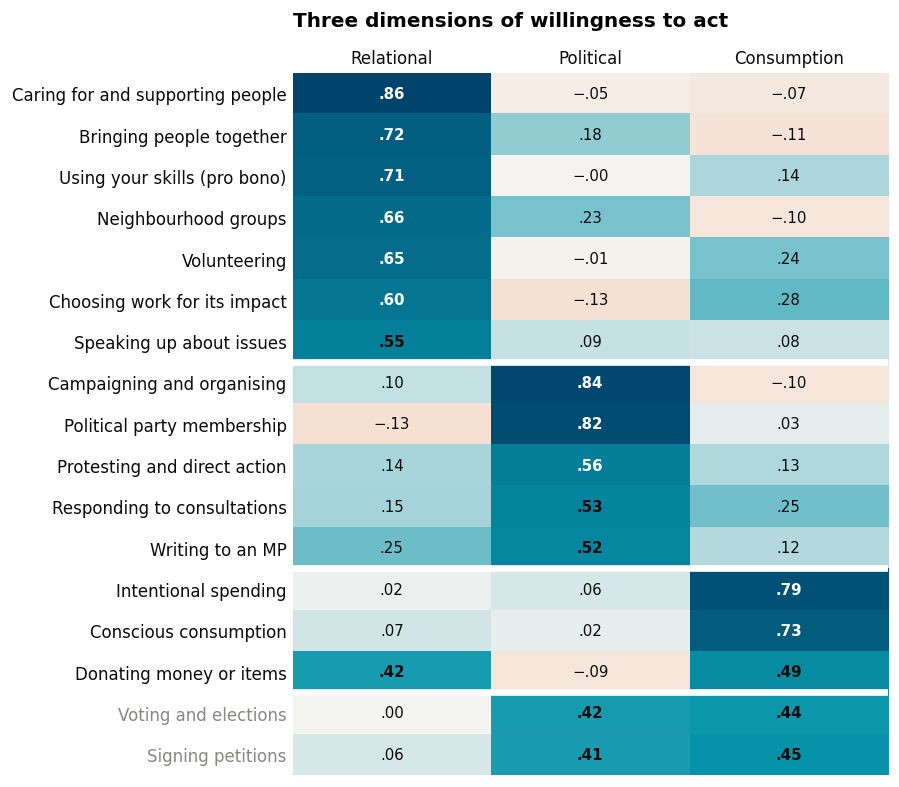

In [27]:
# Short display labels, matched on the same kind of distinctive phrase used in 4.4
SHORT = {'Speaking up': 'Speaking up about issues', 'Donating': 'Donating money or items',
         'Volunteering': 'Volunteering', 'Using your skills': 'Using your skills (pro bono)',
         'Choosing work': 'Choosing work for its impact', 'neighbourhood': 'Neighbourhood groups',
         'Caring for': 'Caring for and supporting people', 'Bringing people': 'Bringing people together',
         'Voting': 'Voting and elections', 'petitions': 'Signing petitions',
         'consultations': 'Responding to consultations', 'MP or other': 'Writing to an MP',
         'political party': 'Political party membership', 'Campaigning': 'Campaigning and organising',
         'Protesting': 'Protesting and direct action',
         'intentional about where': 'Intentional spending',
         'conscious of your consumption': 'Conscious consumption'}


def short(item):
    return next(v for k, v in SHORT.items() if k in item)


# F1, F2 and F3 are relational, political and consumption (4.3)
load = pd.DataFrame(fa.loadings_, index=actions, columns=['Relational', 'Political', 'Consumption'])
groups = [('Relational', f1_items), ('Political', f2_items), ('Consumption', f3_items)]

# Rows: each composite's items, strongest loading first, then the cross-loading items
in_composites = f1_items + f2_items + f3_items
order = []
for name, items in groups:
    order += list(load.loc[items, name].sort_values(ascending=False).index)
excluded = [a for a in actions if a not in in_composites]
order += excluded

fig, ax = plt.subplots(figsize=(6.4, 7.6))
ax.imshow(load.loc[order].values, cmap=DIVERGING, vmin=-0.9, vmax=0.9, aspect='auto')
for i, item in enumerate(order):
    for j, name in enumerate(load.columns):
        v = load.loc[item, name]
        ax.text(j, i, fmt(v).replace('+', ''), ha='center', va='center', fontsize=9,
                fontweight='bold' if abs(v) >= 0.32 else 'normal',
                color='white' if abs(v) >= 0.55 else INK)

# White rules between the composite groups
edge = 0
for _, items in groups:
    edge += len(items)
    ax.axhline(edge - 0.5, color='white', lw=4)

ax.set_yticks(range(len(order)))
ax.set_yticklabels([short(a) for a in order], color=INK)
for a, lab in zip(order, ax.get_yticklabels()):
    if a in excluded:
        lab.set_color(MUTED)
ax.set_xticks(range(3))
ax.set_xticklabels(load.columns, color=INK)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title('Three dimensions of willingness to act', loc='left', pad=28)
plt.show()

### 4.5 Reliability of the composites

Cronbach's alpha - how consistently a set of items measures the same thing - is .888 for relational, .853 for political and .827 for consumption, all above the .80 conventionally treated as good.

In [28]:
def cronbach_alpha(df):
    k = df.shape[1]
    return (k / (k - 1)) * (1 - df.var(ddof=1).sum() / df.sum(axis=1).var(ddof=1))

for name, items in [('Relational', f1_items), ('Political', f2_items), ('Consumption', f3_items)]:
    print(f"{name} ({len(items)} items): alpha = {cronbach_alpha(csr[items]):.3f}")

Relational (7 items): alpha = 0.888
Political (5 items): alpha = 0.853
Consumption (3 items): alpha = 0.827


### 4.6 Split-half validation

The sample is split into two random halves of 155 and the factor analysis run on each independently. The fixed seed (42) means the split reproduces exactly.

In [29]:
# Fixed seed so the random split is identical every time
rng = np.random.RandomState(42)
# Shuffle the respondents, then take the first 155 and the remaining 155
idx = rng.permutation(csr.index)
half_a, half_b = idx[:155], idx[155:]

# Run the same factor analysis separately on each half
fa_a = FactorAnalyzer(n_factors=3, rotation='oblimin')
fa_a.fit(csr.loc[half_a, actions])

fa_b = FactorAnalyzer(n_factors=3, rotation='oblimin')
fa_b.fit(csr.loc[half_b, actions])

load_a = pd.DataFrame(fa_a.loadings_, index=[a.strip()[:40] for a in actions], columns=['A_F1', 'A_F2', 'A_F3'])
load_b = pd.DataFrame(fa_b.loadings_, index=[a.strip()[:40] for a in actions], columns=['B_F1', 'B_F2', 'B_F3'])

# Show both halves' loadings side by side
pd.concat([load_a, load_b], axis=1).round(2)

,A_F1,A_F2,A_F3,B_F1,B_F2,B_F3
WILL Speaking up about issues you unders,0.50,0.09,0.10,0.54,0.08,0.16
WILL Donating money/items to organisatio,0.33,-0.04,0.55,0.40,-0.16,0.56
WILL Volunteering for a cause/community,0.54,0.02,0.40,0.66,-0.00,0.17
WILL Using your skills to support a caus,0.55,0.02,0.39,0.80,0.06,-0.06
WILL Choosing work based on the positive,0.40,-0.11,0.53,0.71,-0.09,0.11
WILL Participating in neighbourhood grou,0.75,0.15,-0.05,0.56,0.32,-0.08
WILL Caring for and supporting people —,0.83,-0.07,0.01,0.81,-0.03,-0.01
WILL Bringing people together — through,0.81,0.13,-0.12,0.58,0.20,0.05
WILL Voting and engaging with elections,0.03,0.46,0.34,-0.08,0.29,0.64
WILL Signing petitions,0.01,0.46,0.44,0.03,0.30,0.58


Tucker's congruence coefficient compares the two halves' loading patterns. Where the matching factors meet it is .952, .965 and .872 — the first two at or above the .95 that means effectively the same factor, the third within the .85–.94 band of fair similarity (Lorenzo-Seva & ten Berge, 2006) — and no higher than .434 between non-matching factors.  The weaker third factor reflects some overlap in half A, where several relational items also load on consumption (Choosing work .53, Volunteering .40, Using your skills .39).

In [30]:
# How similar two columns of loadings are (1 = identical pattern)
def tucker_congruence(x, y):
    return np.dot(x, y) / (np.sqrt(np.sum(x ** 2)) * np.sqrt(np.sum(y ** 2)))

# Compare every half-A factor with every half-B factor
pd.DataFrame(
    [[tucker_congruence(fa_a.loadings_[:, i], fa_b.loadings_[:, j]) for j in range(3)] for i in range(3)],
    index=['A_F1', 'A_F2', 'A_F3'], columns=['B_F1', 'B_F2', 'B_F3']
).round(3)

,B_F1,B_F2,B_F3
A_F1,0.952,0.213,0.140
A_F2,0.129,0.965,0.385
A_F3,0.434,0.074,0.872


### 4.7 Traits against the dimensions — uncentred

The second part of H2: do traits predict which dimension someone leans towards? This subsection shows the composites as they stand; 4.8 removes general engagement.

Here, nearly every trait correlates with all three composites in the same direction which is the general engagement factor showing through.

In [31]:
# The three composites from section 4.4, reused from here on
comp_cols = ['relational_score', 'political_score', 'consumption_score']

uncentred_rows = []
for trait in traits:
    for col in comp_cols:
        rho, p = spearmanr(csr[trait], csr[col])
        uncentred_rows.append({'trait': trait, 'dimension': col.replace('_score', ''), 'rho': rho, 'p': p})

uncentred_df = pd.DataFrame(uncentred_rows)
# FDR across all 45 (15 traits × 3 dimensions)
uncentred_df['q'] = multipletests(uncentred_df['p'], method='fdr_bh')[1]

# Reshape into a grid
uncentred_df.pivot_table(index='trait', columns='dimension', values='rho').round(3)

dimension,consumption,political,relational
trait,,,
BFI Agreeableness,0.266,0.214,0.303
BFI Conscientiousness,0.028,0.014,0.075
BFI Extraversion,0.090,0.194,0.246
BFI Negative Emotionality,0.015,-0.090,-0.008
BFI Open-Mindedness,0.367,0.239,0.440
VALCEN Achievement,-0.205,-0.210,-0.221
VALCEN Benevolence,0.400,0.298,0.437
VALCEN Conformity,-0.198,-0.300,-0.178
VALCEN Hedonism,0.187,0.141,0.085


### 4.8 Ipsatised composites

The same logic as centring the willingness items (3.6), now for dimensions: each person's three composite scores are centred on their own mean across the three. The correction penalty is much lighter with only 45 tests.

Two survive at q < .05 — Conformity against political, and Universalism against relational — and four at q < .10.

Taken with 3.6, the surviving trait signal across H1 and H2 is narrower than the counts suggest. Three of the four item-level survivors are Conformity against political actions — party membership, campaigning and organising, and protesting and direct action — and the composite-level Conformity result is the same relationship at a coarser resolution. Once general engagement is removed, the trait that predicts which *kind* of action someone leans towards is low Conformity, and it does so consistently across the political items. Universalism against relational and Stimulation against signing petitions are the two further findings.

In [32]:
# Centre each person's three composites on their own mean across those three
comp_centred = csr[comp_cols].sub(csr[comp_cols].mean(axis=1), axis=0)
comp_centred.columns = ['relational_c', 'political_c', 'consumption_c']

# Every trait against every centred composite: 15 × 3 = 45 tests
ips_factor_rows = []
for trait in traits:
    for col in comp_centred.columns:
        rho, p = spearmanr(csr[trait], comp_centred[col])
        ips_factor_rows.append({'trait': trait, 'dimension': col, 'rho': rho, 'p': p})

ips_factor_df = pd.DataFrame(ips_factor_rows)
ips_factor_df['q'] = multipletests(ips_factor_df['p'], method='fdr_bh')[1]

print(f"{(ips_factor_df['q'] < 0.05).sum()} of {len(ips_factor_df)} at q < .05")
ips_factor_df[ips_factor_df['q'] < 0.10].sort_values('q').round(4)

2 of 45 at q < .05


,trait,dimension,rho,p,q
16,VALCEN Conformity,political_c,-0.2221,0.0001,0.0031
24,VALCEN Universalism,relational_c,-0.2150,0.0001,0.0031
15,VALCEN Conformity,relational_c,0.1654,0.0035,0.0523
41,VALCEN Power,consumption_c,-0.1560,0.0059,0.0667


## 5. H3 — Do traits predict archetype resonance, and do archetypes map onto the dimensions?

### 5.1 Why archetypes are treated dimensionally rather than as types

**Not a hypothesis test — a check on an assumption.** K-means clustering on the 10 centred values, 5 personality traits and 17 willingness items, for 2 to 10 clusters.

Silhouette (Rousseeuw, 1987) peaks at .187 at two clusters and declines from there. Kaufman and Rousseeuw (1990) treat .25 or below as no substantial structure, .26–.50 as weak, .51–.70 as reasonable and above .70 as strong.

This doesn't test H3 for the following reasons which justify treating the archetypes dimensionally:

**Conceptually**, the archetypes are non-exclusive by design. Someone can be both Steward and Advocate, and two people who share one archetype need not share the other. Clustering assigns each person to exactly one group, so it cannot represent the claim being made. H3 is that traits predict *where someone sits on each archetype*, not that people sort into discrete archetype groups.

**Empirically**, k-means did not produce well-separated clusters at any k under this specification. That is one algorithm under one standardisation rather than proof that no structure exists, but it gives no positive reason to treat people as discrete types.

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# The 32 variables from the original people-clustering: 10 values, 5 personality, 17 willingness
people_vars = traits[5:] + traits[:5] + actions
# Standardise each variable (mean 0, SD 1) so no single scale dominates the distances
X_people = StandardScaler().fit_transform(csr[people_vars])

sil_rows = []
for k in range(2, 11):
    # Group people into k clusters; random_state fixes the result so it reproduces
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_people)
    sil_rows.append({'k': k, 'silhouette': silhouette_score(X_people, labels)})

pd.DataFrame(sil_rows).round(3)

,k,silhouette
0,2,0.187
1,3,0.116
2,4,0.099
3,5,0.090
4,6,0.076
5,7,0.071
6,8,0.077
7,9,0.065
8,10,0.067


### H3 Part 1 — Do traits predict archetype resonance?

### 5.2 Extreme-scorer analysis

The whole-sample trait–archetype correlations are in 3.1 (Traits–Archetypes block). This asks a narrower question - whether an *extreme* score signals a resonance that the whole-sample correlation averages away.

For each trait, the top 25% of scorers are compared with the other 75% on each archetype rating, using Mann-Whitney U.

`gap` is the difference in mean archetype rating between the two groups. FDR-corrected across all 90.

27 of the 90 survive at q < .05.

In [34]:
from scipy.stats import mannwhitneyu

# For one trait: compare its top 25% with everyone else on each outcome
def extreme_scorer_gaps(trait, outcomes):
    # True for anyone at or above the 75th percentile on this trait
    top25 = csr[trait] >= csr[trait].quantile(0.75)
    rows = []
    for outcome in outcomes:
        top_vals = csr.loc[top25, outcome]
        rest_vals = csr.loc[~top25, outcome]
        # Mann-Whitney U compares the two groups by rank, so it suits 1–4 ratings
        stat, p = mannwhitneyu(top_vals, rest_vals, alternative='two-sided')
        rows.append({'trait': trait, 'outcome': outcome,
                     'rest_mean': rest_vals.mean(), 'top25_mean': top_vals.mean(),
                     'gap': top_vals.mean() - rest_vals.mean(), 'p': p})
    return pd.DataFrame(rows)

# All 15 traits against all 6 archetypes: 90 tests
extreme_df = pd.concat([extreme_scorer_gaps(t, archetypes) for t in traits], ignore_index=True)
extreme_df['q'] = multipletests(extreme_df['p'], method='fdr_bh')[1]

print(f"{(extreme_df['q'] < 0.05).sum()} of {len(extreme_df)} at q < .05")

27 of 90 at q < .05


The significant results for each archetype.

Challenger's Stimulation (.680) and Conformity (−.676) gaps are the largest in the set.

In [35]:
# One table per archetype, significant results only
for arc in archetypes:
    print(f"\n{arc}")
    display(extreme_df[(extreme_df['outcome'] == arc) & (extreme_df['q'] < 0.05)]
            .sort_values('gap', ascending=False)[['trait', 'gap', 'p', 'q']].round(4))


ARC Caregiver


,trait,gap,p,q
42,VALCEN Benevolence,0.4990,0.0000,0.0000
24,BFI Open-Mindedness,0.4051,0.0006,0.0033
6,BFI Agreeableness,0.3953,0.0003,0.0018
12,BFI Conscientiousness,0.3318,0.0023,0.0115
78,VALCEN Power,-0.4277,0.0002,0.0018



ARC Advocate


,trait,gap,p,q
1,BFI Extraversion,0.5362,0.0000,0.0000
25,BFI Open-Mindedness,0.4539,0.0001,0.0005
61,VALCEN Stimulation,0.3722,0.0008,0.0042
31,VALCEN Conformity,-0.3463,0.0056,0.0219



ARC Connector


...

,trait,gap,p,q
45,VALCEN Benevolence,0.2887,0.0026,0.0121
15,BFI Conscientiousness,0.2798,0.0040,0.0171
51,VALCEN Universalism,0.2798,0.0032,0.0144
63,VALCEN Stimulation,0.2674,0.0055,0.0219



ARC Challenger


,trait,gap,p,q
64,VALCEN Stimulation,0.6797,0.0000,0.0000
58,VALCEN Self-Direction,0.5696,0.0000,0.0000
28,BFI Open-Mindedness,0.5164,0.0000,0.0001
4,BFI Extraversion,0.5157,0.0000,0.0001
40,VALCEN Tradition,-0.3308,0.0072,0.0269
34,VALCEN Conformity,-0.6756,0.0000,0.0000



ARC Catalyst


,trait,gap,p,q
59,VALCEN Self-Direction,0.6141,0.0000,0.0000
5,BFI Extraversion,0.5174,0.0000,0.0001
65,VALCEN Stimulation,0.4326,0.0003,0.0019
29,BFI Open-Mindedness,0.4162,0.0004,0.0025
89,VALCEN Security,-0.3130,0.0091,0.0315
35,VALCEN Conformity,-0.3186,0.0125,0.0418


### 5.3 How strongly people resonate with the archetypes

77% of people rate at least one archetype “very much like me”, and 221 of 310 (71.3%) tie for their top archetype.

In [36]:
arc_scores = csr[archetypes]
# For each person, count how many archetypes equal their highest rating.
# More than one means a tie
n_tied = (arc_scores.eq(arc_scores.max(axis=1), axis=0).sum(axis=1) > 1).sum()
print(f"Tied for top archetype: {n_tied} of {len(csr)} ({n_tied / len(csr) * 100:.1f}%)")

Tied for top archetype: 221 of 310 (71.3%)


**Figure: how strongly people resonate with the archetypes.** Left: the spread of ratings for each archetype. Right: how many of the six each person rated "very much like me".

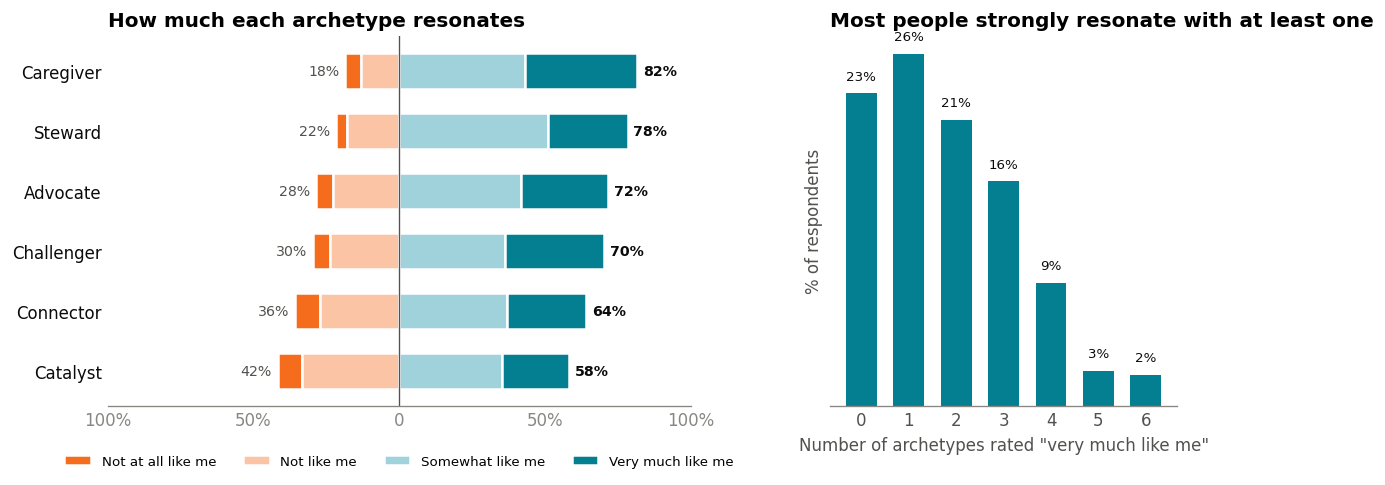

Rated at least one archetype 'very much like me': 77.1%


In [37]:
SCALE = {1: 'Not at all like me', 2: 'Not like me', 3: 'Somewhat like me', 4: 'Very much like me'}
SHADES = {1: ORANGE, 2: '#fbc4a4', 3: '#9fd2db', 4: AZURE}

pct = (csr[archetypes].apply(lambda s: s.value_counts(normalize=True))
       .reindex([1, 2, 3, 4]).fillna(0) * 100).T
pct.index = [a.replace('ARC ', '') for a in pct.index]
# Most resonant at the top
pct = pct.loc[(pct[3] + pct[4]).sort_values().index]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11.5, 4),
                              gridspec_kw={'width_ratios': [2.1, 1.25], 'wspace': 0.3})

# Left figure: 'not like me' ratings run left of zero, 'like me' ratings to the right
y = np.arange(len(pct))
for k, start in [(1, -(pct[1] + pct[2])), (2, -pct[2]), (3, 0), (4, pct[3])]:
    ax.barh(y, pct[k], left=start, color=SHADES[k], height=0.6,
            edgecolor='white', linewidth=1.5, label=SCALE[k])
for i, (lo, hi) in enumerate(zip(pct[1] + pct[2], pct[3] + pct[4])):
    ax.text(-lo - 2, i, f'{lo:.0f}%', ha='right', va='center', fontsize=8.5, color=INK2)
    ax.text(hi + 2, i, f'{hi:.0f}%', ha='left', va='center', fontsize=8.5, color=INK, fontweight='bold')
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(pct.index, color=INK)
ax.set_xlim(-100, 100)
ax.set_xticks([-100, -50, 0, 50, 100])
ax.set_xticklabels(['100%', '50%', '0', '50%', '100%'], color=MUTED)
ax.tick_params(length=0)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.legend(ncol=4, frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.1))
ax.set_title('How much each archetype resonates', loc='left')

# Right figure: number of archetypes each person rated 4
n_top = (csr[archetypes] == 4).sum(axis=1).value_counts().reindex(range(7), fill_value=0)
share = n_top / len(csr) * 100
ax2.bar(share.index, share.values, color=AZURE, width=0.65)
for k, v in share.items():
    ax2.text(k, v + 1, f'{v:.0f}%', ha='center', fontsize=8, color=INK)
ax2.set_xticks(range(7))
ax2.set_xlabel('Number of archetypes rated "very much like me"')
ax2.set_ylabel('% of respondents')
ax2.set_yticks([])
ax2.tick_params(length=0)
for s in ['top', 'right', 'left']:
    ax2.spines[s].set_visible(False)
ax2.set_title('Most people strongly resonate with at least one', loc='left')
plt.show()

print(f"Rated at least one archetype 'very much like me': {(n_top[1:].sum() / len(csr)):.1%}")

### 5.4 How much of archetype resonance do traits explain?

Because archetypes are deliberately non-exclusive and most people tie for their highest rating (5.3), a single model predicting each person’s top archetype isn’t possible, so each archetype gets its own model.

All 15 traits are represented in each model to avoid choosing predictors from the same data the models are fitted to, which would inflate the result.

The ten centred values sum to zero for each person, so any one can be calculated exactly from the other nine, and the model cannot be estimated with all ten. Hedonism is left out of the model here but R² is identical whichever is dropped so the choice is inconsequential.

Adjusted R², which penalises the number of predictors, runs from .295 for Challenger down to .066 for Steward, all significant at p < .002. Challenger is the most trait-predictable archetype and Steward the least — the latter supporting the cause-grounded reading of Steward in 5.9.

R² describes resonance as rated, so it includes general resonance (rating every archetype highly) as well as distinctive preference. Whether the trait links survive once general resonance is removed is tested in 5.5.

Individual coefficients are not reported, as each shows what a trait adds beyond the other thirteen rather than whether it relates to the archetype. Section 5.5 answers the which-traits question with correlations instead.

In [38]:
import statsmodels.api as sm

# One model per archetype; Hedonism dropped
predictors = [t for t in traits if t != 'VALCEN Hedonism']

X = sm.add_constant(csr[predictors])

reg_rows = []
for arc in archetypes:
    m = sm.OLS(csr[arc], X).fit()
    reg_rows.append({'archetype': arc.replace('ARC ', ''),
                     'R2': m.rsquared, 'adj_R2': m.rsquared_adj,
                     'F': m.fvalue, 'p': m.f_pvalue})

print(f"{len(predictors)} predictors, n = {len(csr)}")
pd.DataFrame(reg_rows).sort_values('adj_R2', ascending=False).round(4)

14 predictors, n = 310


,archetype,R2,adj_R2,F,p
4,Challenger,0.3271,0.2952,10.2450,0.0000
0,Caregiver,0.2584,0.2232,7.3421,0.0000
5,Catalyst,0.2401,0.2041,6.6586,0.0000
1,Advocate,0.2366,0.2003,6.5289,0.0000
2,Connector,0.1942,0.1560,5.0790,0.0000
3,Steward,0.1078,0.0655,2.5460,0.0018


**Figure: how much of each archetype the traits explain.** Adjusted R² from the six models above.

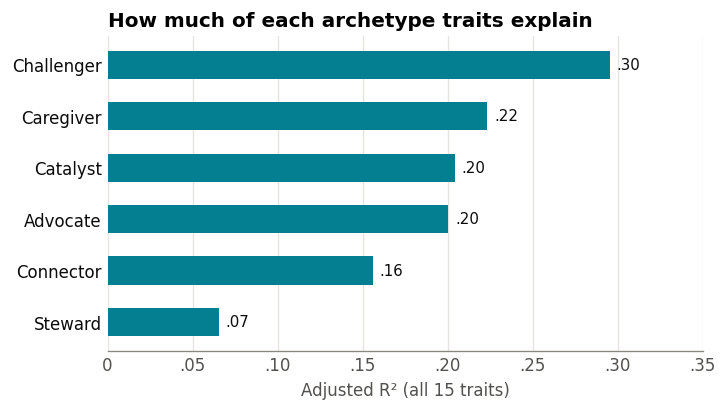

In [39]:
reg = pd.DataFrame(reg_rows).sort_values('adj_R2')

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.barh(reg['archetype'], reg['adj_R2'], color=AZURE, height=0.55)
for i, v in enumerate(reg['adj_R2']):
    ax.text(v + 0.004, i, f'{v:.2f}'.replace('0.', '.'), va='center', fontsize=9, color=INK)
ax.set_xlabel('Adjusted R² (all 15 traits)')
ax.set_xlim(0, 0.35)
ax.xaxis.set_major_formatter(lambda x, _: f'{x:.2f}'.replace('0.', '.') if x else '0')
ax.grid(axis='x', color=GRID)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.tick_params(axis='y', labelcolor=INK)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.set_title('How much of each archetype traits explain', loc='left')
plt.show()

### 5.5 Centred archetypes

The same logic as centring willingness and dimensions, applied to the archetypes. Each person’s six archetype ratings are centred on their own mean across the six. This removes general resonance (people who rate every archetype highly) and leaves relative preference - which archetypes someone rates above or below their own average.

Only 14 of the 310 gave all six archetypes the same rating, so ample variance remains after centring. Trait associations largely survive: 38 at q < .05 uncentred, 29 centred.

**This is the headline result for H3.** Set it against section 3.6, where removing general engagement from the willingness items cut significant trait associations from 186 to 4. Trait–archetype associations remain far more numerous after centring than trait–action associations. People who resonate with an archetype appear to share a trait profile, even where they don't act distinctively. The two comparisons aren't exactly the same (different numbers of tests, different outcome structures, different transformations) so this is descriptive rather than formal.

Centring shows Extraversion splitting the six cleanly, positive for the four outward-facing archetypes and negative for Caregiver and Steward. It also separates Challenger from Catalyst. In 5.2 the two share much the same profile; after centring, low Conformity and Tradition, Stimulation and Open-Mindedness are distinctive of Challenger, while Catalyst is distinguished by Power and lower Agreeableness.

(Caveat: Some negatives are partly structural - the six centred scores sum to zero per person, so a trait that raises some archetypes must lower at least one of the others.)

In [40]:
# Centre each person's six archetype ratings on their own mean across the six
arc_centred = csr[archetypes].sub(csr[archetypes].mean(axis=1), axis=0)
arc_centred.columns = [a.replace('ARC ', '') + ' [c]' for a in archetypes]

# Count people who gave all six archetypes the same rating; centring leaves them with all zeros
n_flat = (csr[archetypes].nunique(axis=1) == 1).sum()
print(f"People who gave all six archetypes the same rating: {n_flat} of {len(csr)}")

People who gave all six archetypes the same rating: 14 of 310


Traits against centred archetypes, FDR-corrected across the 90, alongside the same 90 correlations on *uncentred* archetypes, corrected within these 90 rather than across all 713 as in 3.1, so the two counts are comparable.

A sharp drop after centring would mean much of the apparent association was general resonance (as with willingness in 3.6) but it largely holds up.

In [41]:
# Each trait against each archetype, uncentred and centred, so the two can be compared
arc_c_rows = []
for trait in traits:
    for arc, col in zip(archetypes, arc_centred.columns):
        rho_u, p_u = spearmanr(csr[trait], csr[arc])
        rho_c, p_c = spearmanr(csr[trait], arc_centred[col])
        arc_c_rows.append({'trait': trait, 'archetype': arc.replace('ARC ', ''),
                           'rho_uncentred': rho_u, 'p_uncentred': p_u,
                           'rho_centred': rho_c, 'p_centred': p_c})

arc_c_df = pd.DataFrame(arc_c_rows)
# Correct each version separately within its own 90 tests
arc_c_df['q_uncentred'] = multipletests(arc_c_df['p_uncentred'], method='fdr_bh')[1]
arc_c_df['q_centred'] = multipletests(arc_c_df['p_centred'], method='fdr_bh')[1]

print(f"Uncentred: {(arc_c_df['q_uncentred'] < 0.05).sum()} of {len(arc_c_df)} at q < .05")
print(f"Centred:   {(arc_c_df['q_centred'] < 0.05).sum()} of {len(arc_c_df)} at q < .05")

display(arc_c_df.pivot_table(index='trait', columns='archetype', values='rho_centred').round(3))
arc_c_df[arc_c_df['q_centred'] < 0.10].sort_values('q_centred')[
    ['trait', 'archetype', 'rho_uncentred', 'rho_centred', 'p_centred', 'q_centred']].round(4)

Uncentred: 38 of 90 at q < .05
Centred:   29 of 90 at q < .05


archetype,Advocate,Caregiver,Catalyst,Challenger,Connector,Steward
trait,,,,,,
BFI Agreeableness,0.042,0.247,-0.160,-0.040,-0.086,-0.030
BFI Conscientiousness,-0.136,0.066,-0.025,-0.083,0.047,0.061
BFI Extraversion,0.180,-0.228,0.141,0.157,0.188,-0.286
BFI Negative Emotionality,-0.016,0.163,-0.081,-0.099,-0.056,0.047
BFI Open-Mindedness,0.068,-0.028,0.042,0.220,-0.050,-0.173
VALCEN Achievement,-0.014,-0.086,-0.017,0.037,0.164,-0.069
VALCEN Benevolence,-0.057,0.290,-0.107,-0.044,-0.176,0.040
VALCEN Conformity,-0.070,0.265,-0.055,-0.335,0.083,0.057
VALCEN Hedonism,-0.009,0.043,-0.056,0.068,-0.036,0.025


,trait,archetype,rho_uncentred,rho_centred,p_centred,q_centred
34,VALCEN Conformity,Challenger,-0.4046,-0.3354,0.0000,0.0000
78,VALCEN Power,Caregiver,-0.2544,-0.3027,0.0000,0.0000
64,VALCEN Stimulation,Challenger,0.4460,0.2990,0.0000,0.0000
42,VALCEN Benevolence,Caregiver,0.3592,0.2898,0.0000,0.0000
3,BFI Extraversion,Steward,0.0242,-0.2863,0.0000,0.0000
58,VALCEN Self-Direction,Challenger,0.3937,0.2764,0.0000,0.0000
30,VALCEN Conformity,Caregiver,0.0916,0.2650,0.0000,0.0000
50,VALCEN Universalism,Connector,-0.1169,-0.2588,0.0000,0.0000
6,BFI Agreeableness,Caregiver,0.3155,0.2474,0.0000,0.0001
40,VALCEN Tradition,Challenger,-0.3074,-0.2351,0.0000,0.0003


**Figure: what survives centring.** Trait associations that survive FDR correction, before and after removing each person's general level. Trait–action counts come from 3.6, each side corrected within its own 255 tests. Trait–archetype counts come from the cell above, each side corrected within its own 90. Trait–dimension links (not shown) show the same drop as trait–action links (2 of 45 survive after centring, 4.8).

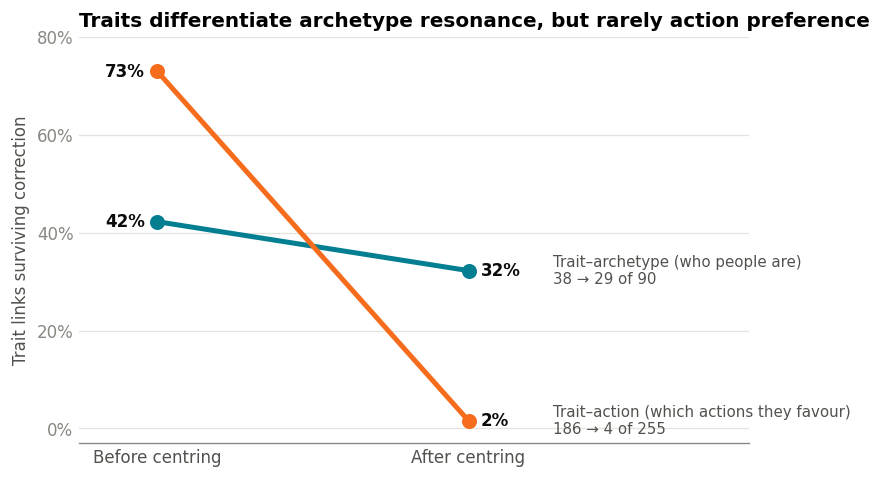

In [42]:
action_before = (ta['q_255'] < 0.05).sum()
action_after  = (ipsative_df['q'] < 0.05).sum()
arc_before    = (arc_c_df['q_uncentred'] < 0.05).sum()
arc_after     = (arc_c_df['q_centred'] < 0.05).sum()

lines = [
    ('Trait–archetype (who people are)', arc_before, arc_after, len(arc_c_df), AZURE),
    ('Trait–action (which actions they favour)', action_before, action_after, len(ta), ORANGE),
]

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for label, before, after, total, colour in lines:
    y = [before / total * 100, after / total * 100]
    ax.plot([0, 1], y, color=colour, lw=3, marker='o', ms=8, zorder=3)
    ax.text(-0.04, y[0], f'{y[0]:.0f}%', ha='right', va='center', fontweight='bold', color=INK)
    ax.text(1.04, y[1], f'{y[1]:.0f}%', ha='left', va='center', fontweight='bold', color=INK)
    ax.text(1.27, y[1], f'{label}\n{before} → {after} of {total}', ha='left', va='center',
            fontsize=9, color=INK2)

ax.set_xlim(-0.25, 1.9)
ax.set_ylim(-3, 80)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Before centring', 'After centring'])
ax.set_yticks(range(0, 81, 20))
ax.set_yticklabels([f'{v}%' for v in range(0, 81, 20)], color=MUTED)
ax.set_ylabel('Trait links surviving correction')
ax.grid(axis='y', color=GRID)
ax.tick_params(length=0)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.set_title('Traits differentiate archetype resonance, but rarely action preference', loc='left')
plt.show()

### H3 Part 2 — Do archetypes map onto the dimensions?

### 5.6 Archetypes against the composites — uncentred

Archetype ratings against the raw composites from section 4.4, before any centring. As expected, general engagement dominates here. 16 of the 18 correlations are significant, and both non-significant pairs are against consumption.

Two findings of note: 

**Advocate and Challenger have the strongest associations** — but they are also the least *differentiated*. Strong on everything is not the same as leaning towards anything.

**Caregiver is the most differentiated**: relational .378 against .164 for its next highest. Connector’s correlations range most widely, from relational (.286) down to consumption (−.016), but its top two are closer together than Caregiver’s.

In [43]:
# Archetypes against the raw composites, before any centring
arc_uncentred_rows = []
for arc in archetypes:
    for col in comp_cols:
        rho, p = spearmanr(csr[arc], csr[col])
        arc_uncentred_rows.append({'archetype': arc.replace('ARC ', ''),
                                   'dimension': col.replace('_score', ''), 'rho': rho, 'p': p})

arc_uncentred_df = pd.DataFrame(arc_uncentred_rows)
arc_uncentred_df['q'] = multipletests(arc_uncentred_df['p'], method='fdr_bh')[1]

print(f"{(arc_uncentred_df['q'] < 0.05).sum()} of {len(arc_uncentred_df)} at q < .05")
arc_uncentred_df.pivot_table(index='archetype', columns='dimension', values='rho').round(3)

16 of 18 at q < .05


dimension,consumption,political,relational
archetype,,,
Advocate,0.214,0.427,0.439
Caregiver,0.164,0.134,0.378
Catalyst,0.082,0.156,0.281
Challenger,0.278,0.342,0.335
Connector,-0.016,0.163,0.286
Steward,0.242,0.184,0.171


### 5.7 Behavioural tilt

Archetype ratings against the ipsatised composites from section 4.8 — does each archetype lean towards a dimension, independent of how engaged the person is?

Because the three centred composites sum to zero for each person, a positive tilt towards one dimension must be balanced by a negative tilt away from at least one other, so the finding is in which dimensions attract a positive tilt.

Nine survive at q < .05 and one more at q < .10. Five of the six archetypes show at least one significant positive tilt — Advocate and Challenger towards political, Caregiver, Connector and Catalyst towards relational. Steward shows none, and no archetype shows a *significant* positive tilt towards consumption; Steward's +.042 is positive but not significant.

In [44]:
# Archetypes against the centred composites from section 4.8
tilt_rows = []
for arc in archetypes:
    for col in comp_centred.columns:
        rho, p = spearmanr(csr[arc], comp_centred[col])
        tilt_rows.append({'archetype': arc.replace('ARC ', ''), 'dimension': col, 'rho': rho, 'p': p})

tilt_df = pd.DataFrame(tilt_rows)
tilt_df['q'] = multipletests(tilt_df['p'], method='fdr_bh')[1]

print(f"{(tilt_df['q'] < 0.05).sum()} of {len(tilt_df)} at q < .05")
display(tilt_df.pivot_table(index='archetype', columns='dimension', values='rho').round(3))
tilt_df[tilt_df['q'] < 0.10].sort_values('q').round(4)

9 of 18 at q < .05


dimension,consumption_c,political_c,relational_c
archetype,,,
Advocate,-0.264,0.242,0.017
Caregiver,-0.032,-0.133,0.227
Catalyst,-0.165,0.059,0.139
Challenger,-0.110,0.146,-0.056
Connector,-0.249,0.062,0.205
Steward,0.042,0.033,-0.096


,archetype,dimension,rho,p,q
5,Advocate,consumption_c,-0.2638,0.0000,0.0000
8,Connector,consumption_c,-0.2493,0.0000,0.0001
4,Advocate,political_c,0.2415,0.0000,0.0001
0,Caregiver,relational_c,0.2274,0.0001,0.0002
6,Connector,relational_c,0.2050,0.0003,0.0010
17,Catalyst,consumption_c,-0.1649,0.0036,0.0108
13,Challenger,political_c,0.1462,0.0100,0.0256
15,Catalyst,relational_c,0.1393,0.0141,0.0318
1,Caregiver,political_c,-0.1326,0.0195,0.0391
14,Challenger,consumption_c,-0.1100,0.0530,0.0954


**Figure: trait profiles and behavioural lean of each archetype.** A: traits against centred archetypes (5.5). B: archetypes against the centred composites (5.7). Coloured cells are significant at q < .05; grey cells are not. Archetypes are grouped by their lean: political, relational, then none (Steward).

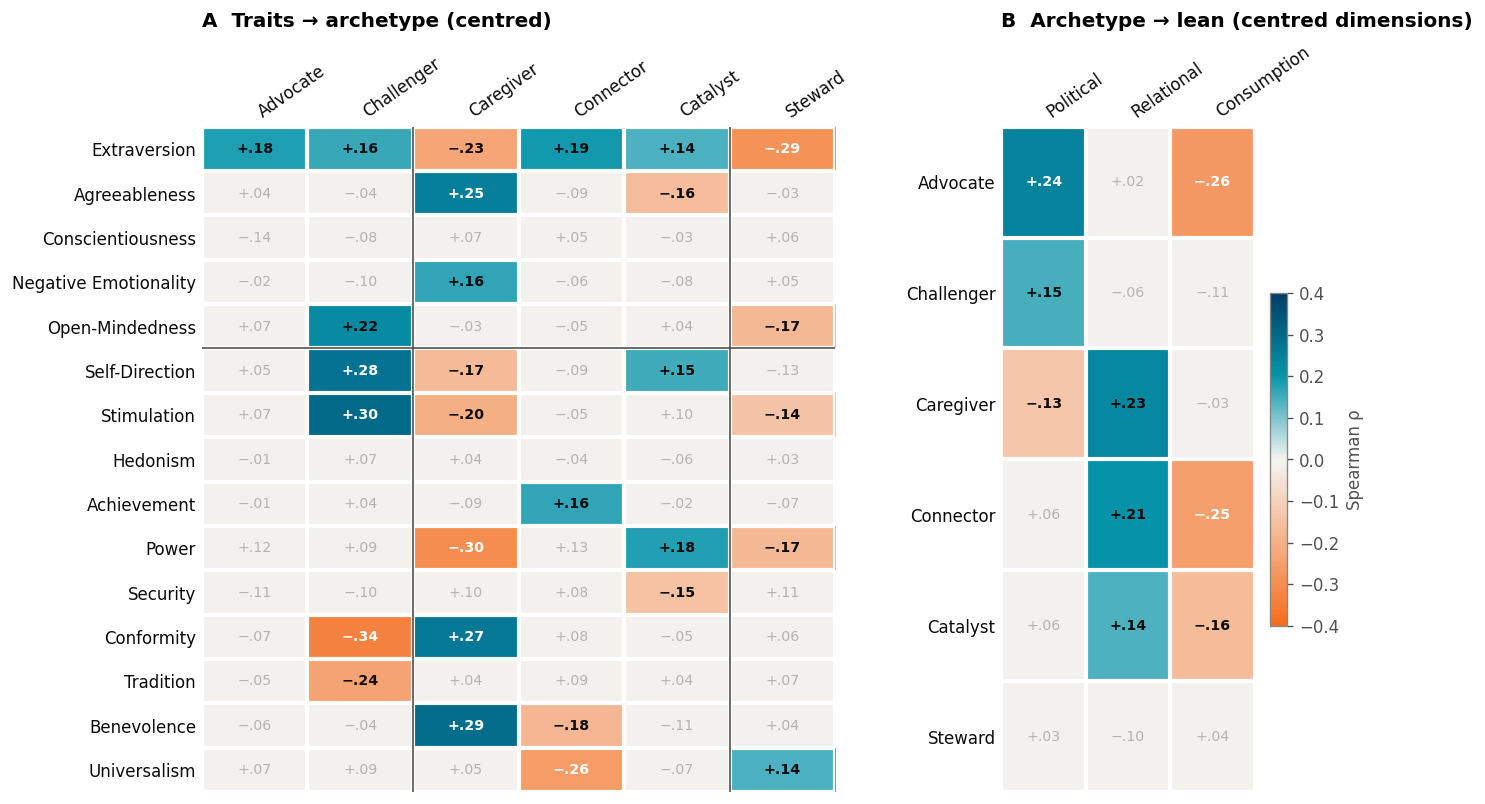

In [45]:
ARC_ORDER = ['Advocate', 'Challenger', 'Caregiver', 'Connector', 'Catalyst', 'Steward']
# Personality traits first, then the Schwartz values in their circular order
TRAIT_ORDER = ['BFI Extraversion', 'BFI Agreeableness', 'BFI Conscientiousness',
               'BFI Negative Emotionality', 'BFI Open-Mindedness',
               'VALCEN Self-Direction', 'VALCEN Stimulation', 'VALCEN Hedonism',
               'VALCEN Achievement', 'VALCEN Power', 'VALCEN Security', 'VALCEN Conformity',
               'VALCEN Tradition', 'VALCEN Benevolence', 'VALCEN Universalism']
DIM_ORDER = ['political_c', 'relational_c', 'consumption_c']


def grid(df, rows, cols, row_key, col_key, value, qcol):
    rho = df.pivot_table(index=row_key, columns=col_key, values=value).loc[rows, cols]
    sig = df.pivot_table(index=row_key, columns=col_key, values=qcol).loc[rows, cols] < 0.05
    return rho, sig


def draw(ax, rho, sig, lim=0.4):
    # Non-significant cells are drawn grey by masking them out of the colour scale
    shown = np.where(sig, rho, np.nan)
    ax.set_facecolor('#f2f1ee')
    ax.imshow(shown, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect='auto')
    for i in range(rho.shape[0]):
        for j in range(rho.shape[1]):
            v = rho.iat[i, j]
            ax.text(j, i, fmt(v), ha='center', va='center', fontsize=8.5,
                    fontweight='bold' if sig.iat[i, j] else 'normal',
                    color=('white' if abs(v) > lim * 0.6 else INK) if sig.iat[i, j] else '#b5b3ad')
    # White gaps between cells
    ax.set_xticks(np.arange(-0.5, rho.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, rho.shape[0]), minor=True)
    ax.grid(which='minor', color='white', lw=2.5)
    ax.tick_params(which='both', length=0)
    for s in ax.spines.values():
        s.set_visible(False)


rho_a, sig_a = grid(arc_c_df, TRAIT_ORDER, ARC_ORDER, 'trait', 'archetype',
                    'rho_centred', 'q_centred')
rho_b, sig_b = grid(tilt_df, ARC_ORDER, DIM_ORDER, 'archetype', 'dimension', 'rho', 'q')

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 7.2),
                              gridspec_kw={'width_ratios': [6, 3], 'wspace': 0.35})
draw(ax, rho_a, sig_a)
ax.set_yticks(range(len(TRAIT_ORDER)))
ax.set_yticklabels([t.replace('BFI ', '').replace('VALCEN ', '') for t in TRAIT_ORDER], color=INK)
ax.set_xticks(range(len(ARC_ORDER)))
ax.set_xticklabels(ARC_ORDER, rotation=35, ha='left', color=INK)
ax.xaxis.tick_top()
# Lines separating traits from values, and the three archetype groups
ax.axhline(4.5, color=INK2, lw=1)
for x in [1.5, 4.5]:
    ax.axvline(x, color=INK2, lw=1)
ax.set_title('A  Traits → archetype (centred)', loc='left', pad=60)

draw(ax2, rho_b, sig_b)
ax2.set_yticks(range(len(ARC_ORDER)))
ax2.set_yticklabels(ARC_ORDER, color=INK)
ax2.set_xticks(range(len(DIM_ORDER)))
ax2.set_xticklabels(['Political', 'Relational', 'Consumption'], rotation=35, ha='left', color=INK)
ax2.xaxis.tick_top()
ax2.set_title('B  Archetype → lean (centred dimensions)', loc='left', pad=60)

sm_ = plt.cm.ScalarMappable(cmap=DIVERGING, norm=plt.Normalize(-0.4, 0.4))
fig.colorbar(sm_, ax=ax2, shrink=0.5, label='Spearman ρ')
plt.show()

### Archetype follow-ups (beyond H3)

### 5.8 Cause preference

Archetype ratings against the seven cause categories.

Eight survive at q < .05 and three more at q < .10, with Steward–Planet (.288) the largest. Connector and Catalyst have no surviving association.

In [46]:
# Each archetype against each of the 7 cause categories: 42 tests
cause_rows = []
for arc in archetypes:
    for cause in causes:
        rho, p = spearmanr(csr[arc], csr[cause])
        cause_rows.append({'archetype': arc.replace('ARC ', ''), 'cause': cause.replace('CAT ', ''), 'rho': rho, 'p': p})

cause_arc_df = pd.DataFrame(cause_rows)
cause_arc_df['q'] = multipletests(cause_arc_df['p'], method='fdr_bh')[1]

print(f"{(cause_arc_df['q'] < 0.05).sum()} of {len(cause_arc_df)} at q < .05")
display(cause_arc_df.pivot_table(index='archetype', columns='cause', values='rho').round(3))
cause_arc_df[cause_arc_df['q'] < 0.10].sort_values('q').round(4)

8 of 42 at q < .05


cause,Animals,Future,Health,Humanitarian,Justice,Planet,Wellbeing
archetype,,,,,,,
Advocate,0.075,0.078,0.045,0.156,0.180,0.136,0.128
Caregiver,0.179,0.068,0.150,0.088,0.101,0.080,0.081
Catalyst,-0.016,0.025,0.011,0.048,0.060,0.101,0.122
Challenger,-0.033,0.116,0.001,0.043,0.185,0.098,0.209
Connector,-0.051,0.004,-0.034,-0.016,-0.062,0.012,-0.011
Steward,0.205,0.083,-0.042,0.134,-0.019,0.288,0.048


,archetype,cause,rho,p,q
24,Steward,Planet,0.2875,0.0000,0.0000
25,Steward,Animals,0.2054,0.0003,0.0038
29,Challenger,Wellbeing,0.2093,0.0002,0.0038
30,Challenger,Justice,0.1851,0.0011,0.0111
4,Caregiver,Animals,0.1786,0.0016,0.0112
9,Advocate,Justice,0.1799,0.0015,0.0112
12,Advocate,Humanitarian,0.1560,0.0059,0.0354
0,Caregiver,Health,0.1502,0.0081,0.0424
10,Advocate,Planet,0.1363,0.0163,0.0761
26,Steward,Humanitarian,0.1335,0.0187,0.0785


### 5.9 Steward follow-up

Steward has the lowest adjusted R² in 5.4, and its strongest associations are with causes rather than traits: Planet (.288) and Animals (.205) in 5.8. This checks whether those links hold beyond general engagement, by entering both with VLQ Importance as a control, the same aim as centring elsewhere.

**Post-hoc and exploratory.** Planet and Animals were chosen after seeing 5.8, so this describes this sample rather than testing a prediction.

With the others held constant, Planet remains associated with Steward (b = 0.374, p = .014) but Animals does not (b = 0.154, p = .297), so the two share the same signal and Planet carries it. Importance is also associated (b = 0.097, p < .001). The coefficients are on different scales (proportion against 1–10 score), so they shouldn’t be compared by size.

In [47]:
# Planet and Animals together, with VLQ Importance as a control
X_steward = sm.add_constant(csr[['CAT Planet', 'CAT Animals', 'VLQ Importance']])
m_steward = sm.OLS(csr['ARC Steward'], X_steward).fit()
print(m_steward.summary().tables[1])

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              2.1020      0.174     12.050      0.000       1.759       2.445
CAT Planet         0.3737      0.151      2.479      0.014       0.077       0.670
CAT Animals        0.1537      0.147      1.045      0.297      -0.136       0.443
VLQ Importance     0.0970      0.023      4.232      0.000       0.052       0.142


## 6. Stability across recruitment route

A robustness check, not a hypothesis test. Responses came through two routes — a Microsoft Forms link shared across several channels (222) and SurveySwap, a survey-exchange platform (88) — and section 1.3 shows the two routes recruited demographically different people.

The question is whether the findings hold within each route, not whether the two groups sit at different levels - two groups can differ markedly in level and still share the same relationships. Only the associations that survived FDR in the pooled sample are checked, since the remaining pairs are null and comparing two noisy estimates of zero would say nothing about stability.

The SurveySwap subsample of 88 is adequate for the correlational comparisons in 6.1 and 6.3 but thin for the factor analysis in 6.2, where the result is indicative rather than conclusive.

Individual rho values move between routes, and with n = 222 against n = 88 they are imprecise: differences of up to about ±.23 in rho are consistent with sampling variation (95% band on Fisher’s z), so no formal test is attempted. What matters is a change in direction where both routes are clearly away from zero. A change counts as a reversal only when both values exceed |.10|, a reporting convention rather than a statistical threshold.

The findings hold. All six H1 and H2 associations and 25 of the 29 H3 associations keep their direction in both routes, and the factor structure shows fair similarity across routes.

### 6.1 H1 and H2 — the surviving trait associations

Four item-level associations survived FDR in section 3.6 (H1) and two composite-level associations in section 4.8 (H2). Those six are what the trait findings for H1 and H2 rest on after ipsatisation, so those six are what is checked here.

All six hold in the same direction in both routes, with no substantive reversals and a mean absolute difference of .116.

Four of the six are Conformity against political action — three individual items and the political composite — so the surviving signal across H1 and H2 is largely one association appearing at two resolutions. The weakest of the six is Stimulation against signing petitions, which is −.267 in the Microsoft route and −.052 in SurveySwap.

In [48]:
ms = csr['recruitment'] == 'Microsoft Forms'

REVERSAL_FLOOR = 0.10   # a sign change counts only if both routes are this far from zero


def rho_by_route(pairs, frame):
    """Spearman rho for each (predictor, outcome) pair: pooled, then within each route."""
    rows = [{'predictor': pred, 'outcome': out,
             'rho_all': spearmanr(csr[pred], frame[out])[0],
             'rho_ms': spearmanr(csr.loc[ms, pred], frame.loc[ms, out])[0],
             'rho_ss': spearmanr(csr.loc[~ms, pred], frame.loc[~ms, out])[0]}
            for pred, out in pairs]
    df = pd.DataFrame(rows)
    df['difference'] = df['rho_ms'] - df['rho_ss']
    return df


def reversal_check(df, label):
    """A sign change only counts as a reversal if both routes clear REVERSAL_FLOOR.
    Moderate in one route and near zero in the other is a weaker finding, not a contradicted one."""
    flipped = np.sign(df['rho_ms']) != np.sign(df['rho_ss'])
    substantive = flipped & (df['rho_ms'].abs() >= REVERSAL_FLOOR) & (df['rho_ss'].abs() >= REVERSAL_FLOOR)
    print(f"{label} — {len(df)} associations")
    print(f"  same direction in both routes: {(~flipped).sum()} of {len(df)}")
    print(f"  substantive reversals:         {substantive.sum()}")
    print(f"  mean absolute difference:      {df['difference'].abs().mean():.3f}")


# The four item-level survivors from 3.6 and the two composite-level survivors from 4.8
sig_items = ipsative_df[ipsative_df['q'] < 0.05]
sig_dims = ips_factor_df[ips_factor_df['q'] < 0.05]

h1_h2_stability = pd.concat([rho_by_route(zip(sig_items['trait'], sig_items['action']), will_centred),
                          rho_by_route(zip(sig_dims['trait'], sig_dims['dimension']), comp_centred)],
                         ignore_index=True)

reversal_check(h1_h2_stability, 'H1 and H2')
h1_h2_stability.round(3)

H1 and H2 — 6 associations
  same direction in both routes: 6 of 6
  substantive reversals:         0
  mean absolute difference:      0.116


,predictor,outcome,rho_all,rho_ms,rho_ss,difference
0,VALCEN Conformity,WILL Being a member of a political party [c],-0.243,-0.248,-0.292,0.044
1,VALCEN Conformity,WILL Campaigning and organising [c],-0.212,-0.250,-0.102,-0.148
2,VALCEN Conformity,WILL Protesting and direct action [c],-0.192,-0.232,-0.148,-0.085
3,VALCEN Stimulation,WILL Signing petitions [c],-0.201,-0.267,-0.052,-0.215
4,VALCEN Conformity,political_c,-0.222,-0.231,-0.309,0.078
5,VALCEN Universalism,relational_c,-0.215,-0.269,-0.144,-0.125


### 6.2 H2 — the factor structure

The three-factor oblimin solution from section 4.3, re-run within each route, compared with Tucker's congruence coefficient — the same function defined in 4.6.

At n = 88 the SurveySwap solution has roughly five respondents per item, below the usual guidance for factor analysis. This check is indicative.

Each Microsoft factor matches exactly one SurveySwap factor, at .941, .936 and .859, with no other value above .345. All three fall in the .85–.94 band of fair similarity rather than the .95 and above that would mean equivalence.

The figures sit a little below the split-half values in 4.6 (.952, .965, .872), which is consistent with a smaller and more unequal split being less stable. The third factor is the weakest in both, which suggests its weaker replication is not specific to one recruitment route.

In [49]:
fa_ms = FactorAnalyzer(n_factors=3, rotation='oblimin')
fa_ms.fit(csr.loc[ms, actions])

fa_ss = FactorAnalyzer(n_factors=3, rotation='oblimin')
fa_ss.fit(csr.loc[~ms, actions])

congruence = pd.DataFrame(
    [[tucker_congruence(fa_ms.loadings_[:, i], fa_ss.loadings_[:, j]) for j in range(3)]
     for i in range(3)],
    index=['Microsoft F1', 'Microsoft F2', 'Microsoft F3'],
    columns=['SurveySwap F1', 'SurveySwap F2', 'SurveySwap F3'])

# Each Microsoft factor's closest match on the SurveySwap side
for row in congruence.index:
    best = congruence.loc[row].abs().idxmax()
    print(f"{row} -> {best}: {congruence.loc[row, best]:+.3f}")
print()
congruence.round(3)

Microsoft F1 -> SurveySwap F2: +0.941
Microsoft F2 -> SurveySwap F1: +0.936
Microsoft F3 -> SurveySwap F3: +0.859



,SurveySwap F1,SurveySwap F2,SurveySwap F3
Microsoft F1,0.175,0.941,0.327
Microsoft F2,0.936,0.171,0.218
Microsoft F3,0.345,0.113,0.859


### 6.3 H3 — the surviving trait–archetype associations

The 29 associations that survived FDR in section 5.5, which carry the headline H3 result, sorted by how far the two routes disagree. The rows at the top are where a reversal would appear.

Twenty-five of the 29 hold in the same direction, with two substantive reversals and a mean absolute difference of .139.

**Both reversals involve Self-Direction** — against Caregiver (−.309 Microsoft, +.116 SurveySwap) and against Catalyst (+.242, −.103). The two further sign changes, Stimulation against Steward and Achievement against Connector, fall below the reversal floor: the SurveySwap value is essentially zero in both (|rho| < .02).

**Steward is the least stable archetype.** Four of its five associations fall to near zero in the SurveySwap route, leaving only Open-Mindedness (−.195 against −.159). This is consistent with Steward's low adjusted R² in 5.4 rather than a new problem.

**Challenger is the most stable.** Conformity against Challenger is −.333 and −.280, and Stimulation .277 and .308. Caregiver’s core links also hold (Conformity .277 and .275, Power −.245 and −.382), though its Self-Direction link reverses.

In [50]:
# Survivors from section 5.5; arc_centred columns carry a ' [c]' suffix
sig_arc = arc_c_df[arc_c_df['q_centred'] < 0.05]

h3_stability = rho_by_route(zip(sig_arc['trait'], sig_arc['archetype'] + ' [c]'), arc_centred)
reversal_check(h3_stability, 'H3')

(h3_stability
 .assign(abs_difference=lambda d: d['difference'].abs())
 .sort_values('abs_difference', ascending=False)
 .drop(columns='abs_difference')
 .round(3))

H3 — 29 associations
  same direction in both routes: 25 of 29
  substantive reversals:         2
  mean absolute difference:      0.139


,predictor,outcome,rho_all,rho_ms,rho_ss,difference
18,VALCEN Self-Direction,Caregiver [c],-0.166,-0.309,0.116,-0.425
3,BFI Extraversion,Steward [c],-0.286,-0.382,-0.017,-0.365
20,VALCEN Self-Direction,Catalyst [c],0.152,0.242,-0.103,0.345
2,BFI Extraversion,Connector [c],0.188,0.296,0.022,0.274
22,VALCEN Stimulation,Steward [c],-0.142,-0.196,0.017,-0.213
24,VALCEN Achievement,Connector [c],0.164,0.184,-0.011,0.195
26,VALCEN Power,Steward [c],-0.174,-0.236,-0.046,-0.190
17,VALCEN Universalism,Steward [c],0.141,0.207,0.021,0.186
14,VALCEN Benevolence,Caregiver [c],0.290,0.215,0.399,-0.184
8,BFI Negative Emotionality,Caregiver [c],0.163,0.220,0.046,0.174


## 7. Exploratory — Do traits predict barriers?

*Exploratory, outside H1–H3. Discussed in the application chapter.*

### 7.1 How often each barrier was chosen

Base rates, for context.

In [51]:
# Barriers are 0/1, so each column's mean is the proportion who ticked it (× 100 for a percentage)
(csr[barriers].mean() * 100).sort_values(ascending=False).round(1)

BARR Time                                                              63.2
BARR Energy                                                            41.0
BARR Finding the right opportunities                                   31.0
BARR Confidence                                                        25.5
BARR Initiation (actually doing it)                                    19.0
BARR Not having someone to do it with                                  15.8
BARR None – I'm happy with how active I am in civic/ community life    12.9
dtype: float64

### 7.2 Barriers against traits

Barriers are binary (ticked or not), so these use point-biserial correlation rather than Spearman.

FDR-corrected across all 105 - six survive at q < .05, and a further five at q < .10.

In [52]:
from scipy.stats import pointbiserialr

barrier_rows = []
for trait in traits:
    for barrier in barriers:
        # Point-biserial: the right correlation for a binary variable against a continuous one
        r, p = pointbiserialr(csr[barrier], csr[trait])
        barrier_rows.append({'trait': trait, 'barrier': barrier, 'r': r, 'p': p})

barrier_df = pd.DataFrame(barrier_rows)
barrier_df['q'] = multipletests(barrier_df['p'], method='fdr_bh')[1]

print(f"{(barrier_df['q'] < 0.05).sum()} of {len(barrier_df)} at q < .05")
barrier_df[barrier_df['q'] < 0.10].sort_values('q').round(4)

6 of 105 at q < .05


,trait,barrier,r,p,q
2,BFI Extraversion,BARR Confidence,-0.3041,0.0000,0.0000
23,BFI Negative Emotionality,BARR Confidence,0.2443,0.0000,0.0007
15,BFI Conscientiousness,BARR Energy,-0.2212,0.0001,0.0030
99,VALCEN Security,BARR Energy,-0.1933,0.0006,0.0163
93,VALCEN Power,BARR Confidence,-0.1833,0.0012,0.0250
20,BFI Conscientiousness,BARR None – I'm happy with how active I am in ...,0.1690,0.0028,0.0497
31,BFI Open-Mindedness,BARR Finding the right opportunities,0.1617,0.0043,0.0565
6,BFI Extraversion,BARR None – I'm happy with how active I am in ...,0.1618,0.0043,0.0565
1,BFI Extraversion,BARR Energy,-0.1584,0.0052,0.0604
57,VALCEN Universalism,BARR Energy,0.1458,0.0101,0.0973


### 7.3 The three barriers heuman is designed to address

Finding the right opportunities, confidence and initiation, chosen by 31.0%, 25.5% and 19.0% of respondents. The chart shows their trait links at q < .10 from 7.2. Confidence is linked to lower Extraversion, Power and Stimulation and higher Negative Emotionality; finding the right opportunities only weakly to Open-Mindedness. Initiation has no trait links and is the least common of the three, so its null has the least power.

In the figure ** q < .05, * q < .10.

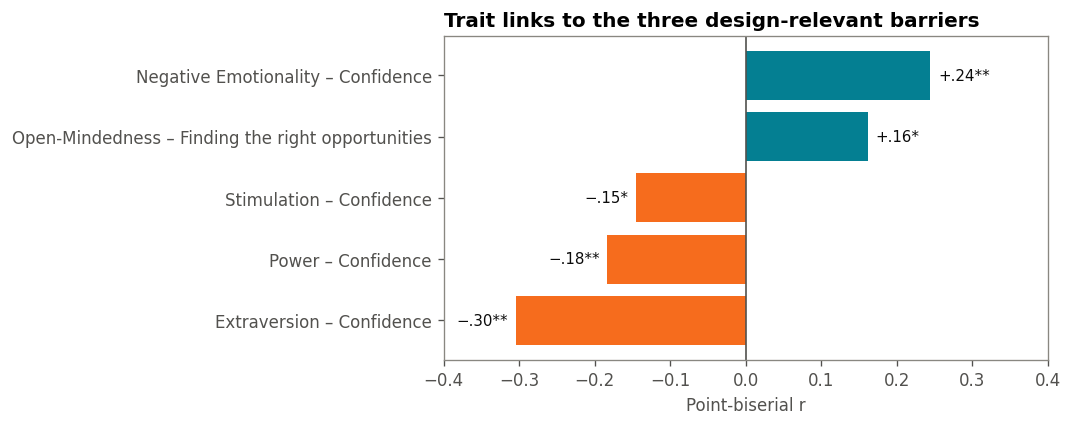

In [53]:
heuman_barriers = [b for b in barriers
                   if any(k in b for k in ['Finding the right', 'Confidence', 'Initiation'])]

sig = barrier_df[barrier_df['barrier'].isin(heuman_barriers)
                 & (barrier_df['q'] < 0.10)].sort_values('r')
labels = [f"{t.replace('BFI ', '').replace('VALCEN ', '')} – {b.replace('BARR ', '')}"
          for t, b in zip(sig['trait'], sig['barrier'])]

fig, ax = plt.subplots(figsize=(6.5, 0.5 * len(sig) + 1))
ax.barh(labels, sig['r'], color=[ORANGE if r < 0 else AZURE for r in sig['r']])
ax.axvline(0, color=INK2, lw=1)
for i, (r, q) in enumerate(zip(sig['r'], sig['q'])):
    ax.text(r + (0.01 if r > 0 else -0.01), i, fmt(r) + ('**' if q < 0.05 else '*'),
            va='center', ha='left' if r > 0 else 'right', fontsize=9, color=INK)
ax.set_xlim(-0.4, 0.4)
ax.set_xlabel('Point-biserial r')
ax.set_title('Trait links to the three design-relevant barriers', loc='left')
plt.show()

## 8. Exploratory — What predicts the value–action gap?

*Exploratory, outside H1–H3. Discussed in the application chapter.*

### 8.1 The gap itself

The gap is stated importance minus reported action.

The mean gap is 1.72, ranging from −4 to +8.

In [54]:
# Gap = importance minus action, so a negative value means acting more than you rate the importance
csr['VLQ C-B Gap'].describe().round(2)

count    310.00
mean       1.72
std        1.97
min       -4.00
25%        0.00
50%        2.00
75%        3.00
max        8.00
Name: VLQ C-B Gap, dtype: float64

### 8.2 The gap against traits

Two of the 15 survive at q < .05: Power (−.190) and Extraversion (−.169), both linked to a smaller gap.

Because the gap is importance minus action, the figure shows each trait against all three (45 tests corrected together; filled dots q < .05, hollow not significant). Extraversion narrows the gap by raising action (.296) more than importance (.207); Stimulation has the same shape (.211 and .165), though its gap link is not significant. Power’s smaller gap is not explained by either side alone, as neither its lower importance (−.123) nor its higher action (.048) is significant. The values that raise importance most (Universalism, Benevolence, Self-Direction and Open-Mindedness, .245–.284) raise action much less (.09–.13), so their gaps lean positive, though none is significant. Achievement lowers importance and action about equally (−.272 and −.229), leaving the gap unchanged.

In [55]:
# Each trait against the gap: 15 tests
gap_trait_rows = []
for trait in traits:
    rho, p = spearmanr(csr[trait], csr['VLQ C-B Gap'])
    gap_trait_rows.append({'trait': trait, 'rho': rho, 'p': p})

gap_traits = pd.DataFrame(gap_trait_rows)
gap_traits['q'] = multipletests(gap_traits['p'], method='fdr_bh')[1]
gap_traits.sort_values('p').round(4)

,trait,rho,p,q
13,VALCEN Power,-0.1900,0.0008,0.0116
0,BFI Extraversion,-0.1687,0.0029,0.0217
7,VALCEN Benevolence,0.1253,0.0274,0.1314
10,VALCEN Stimulation,-0.1172,0.0393,0.1314
6,VALCEN Tradition,-0.1107,0.0516,0.1314
9,VALCEN Self-Direction,0.1064,0.0614,0.1314
4,BFI Open-Mindedness,0.1063,0.0616,0.1314
8,VALCEN Universalism,0.1030,0.0701,0.1314
1,BFI Agreeableness,0.0896,0.1155,0.1926
5,VALCEN Conformity,0.0739,0.1945,0.2917


measure,Action,C-B Gap,Importance
trait,,,
BFI Agreeableness,0.068,0.090,0.168
BFI Conscientiousness,0.116,-0.045,0.098
BFI Extraversion,0.296,-0.169,0.207
BFI Negative Emotionality,-0.101,0.051,-0.077
BFI Open-Mindedness,0.132,0.106,0.269
VALCEN Achievement,-0.229,0.043,-0.272
VALCEN Benevolence,0.092,0.125,0.245
VALCEN Conformity,-0.146,0.074,-0.125
VALCEN Hedonism,0.057,0.040,0.096


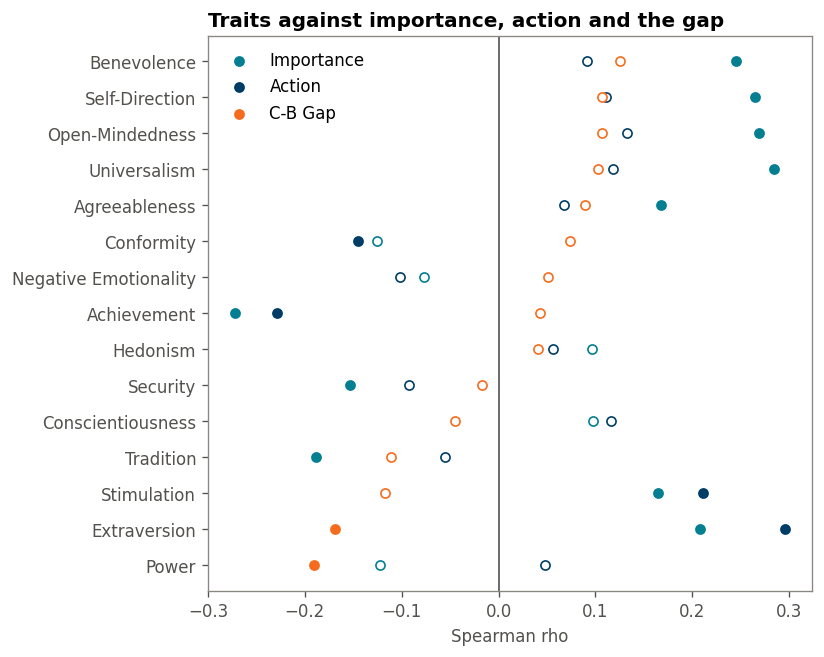

In [56]:
# Each trait against importance, action and the gap: 45 tests
vlq = ['VLQ Importance', 'VLQ Action', 'VLQ C-B Gap']
rows = []
for trait in traits:
    for v in vlq:
        rho, p = spearmanr(csr[trait], csr[v])
        rows.append({'trait': trait, 'measure': v.replace('VLQ ', ''), 'rho': rho, 'p': p})
vlq_df = pd.DataFrame(rows)
vlq_df['q'] = multipletests(vlq_df['p'], method='fdr_bh')[1]
display(vlq_df.pivot_table(index='trait', columns='measure', values='rho').round(3))

# Traits ordered by their link to the gap
order = vlq_df[vlq_df['measure'] == 'C-B Gap'].sort_values('rho')['trait']
fig, ax = plt.subplots(figsize=(6.5, 6))
for measure, colour in [('Importance', AZURE), ('Action', NAVY), ('C-B Gap', ORANGE)]:
    d = vlq_df[vlq_df['measure'] == measure].set_index('trait').loc[order]
    y = np.arange(len(d))
    sig = (d['q'] < 0.05).values
    ax.scatter(d['rho'][sig], y[sig], color=colour, label=measure, s=30)
    ax.scatter(d['rho'][~sig], y[~sig], facecolors='white', edgecolors=colour, s=30)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([t.replace('BFI ', '').replace('VALCEN ', '') for t in order])
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel('Spearman rho')
ax.set_title('Traits against importance, action and the gap', loc='left')
ax.legend(frameon=False)
plt.show()

### 8.3 The gap against barriers

Point-biserial again, since barriers are binary. Four of the seven survive at q < .05 and one more at q < .10. The strongest, “None – I’m happy with how active I am” (−.321), partly restates a small gap, so its size is unsurprising.

The figure splits each barrier’s link into importance and action (21 tests; filled dots q < .05, hollow not significant). Initiation is the clearest: people who cite it act less (−.151) but rate importance no lower (.006), so it is an action barrier. Energy and Time widen the gap without a significant link to either side on its own. Confidence goes with slightly lower importance and action together (−.123 and −.109, neither significant), leaving the gap unchanged (.017).

In [57]:
# Each barrier against the gap
gap_barrier_rows = []
for barrier in barriers:
    r, p = pointbiserialr(csr[barrier], csr['VLQ C-B Gap'])
    gap_barrier_rows.append({'barrier': barrier, 'r': r, 'p': p})

gap_barriers = pd.DataFrame(gap_barrier_rows)
gap_barriers['q'] = multipletests(gap_barriers['p'], method='fdr_bh')[1]
gap_barriers.sort_values('p').round(4)

,barrier,r,p,q
6,BARR None – I'm happy with how active I am in ...,-0.3215,0.0000,0.0000
4,BARR Initiation (actually doing it),0.1913,0.0007,0.0018
1,BARR Energy,0.1904,0.0008,0.0018
0,BARR Time,0.1520,0.0074,0.0129
3,BARR Finding the right opportunities,0.1181,0.0378,0.0529
2,BARR Confidence,0.0167,0.7700,0.8983
5,BARR Not having someone to do it with,-0.0049,0.9314,0.9314


measure,Action,C-B Gap,Importance
barrier,,,
Confidence,-0.109,0.017,-0.123
Energy,-0.085,0.190,0.089
Finding the right opportunities,-0.020,0.118,0.097
Initiation,-0.151,0.191,0.006
None,0.226,-0.321,-0.045
Not having someone to do it with,-0.029,-0.005,-0.042
Time,-0.115,0.152,0.011


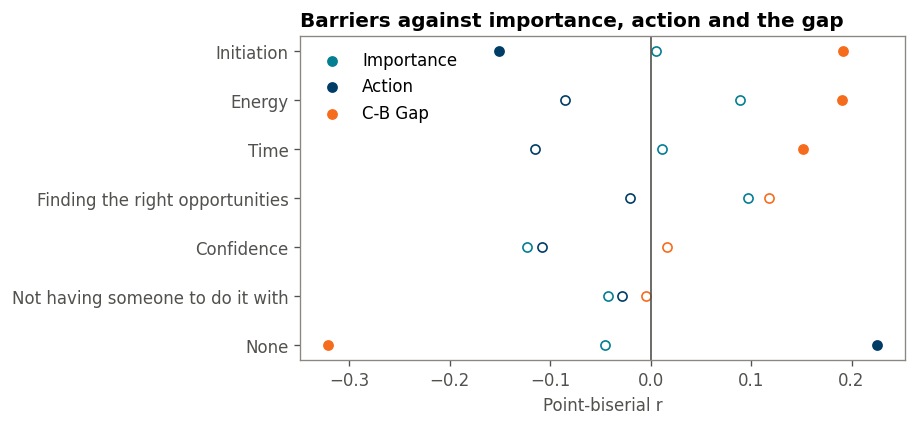

In [58]:
# Each barrier against importance, action and the gap: 21 tests
rows = []
for barrier in barriers:
    for v in vlq:
        r, p = pointbiserialr(csr[barrier], csr[v])
        rows.append({'barrier': barrier.replace('BARR ', '').split(' (')[0].split(' –')[0],
                     'measure': v.replace('VLQ ', ''), 'r': r, 'p': p})
vlq_barr = pd.DataFrame(rows)
vlq_barr['q'] = multipletests(vlq_barr['p'], method='fdr_bh')[1]
display(vlq_barr.pivot_table(index='barrier', columns='measure', values='r').round(3))

# Barriers ordered by their link to the gap; filled dots q < .05, hollow not significant
order = vlq_barr[vlq_barr['measure'] == 'C-B Gap'].sort_values('r')['barrier']
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for measure, colour in [('Importance', AZURE), ('Action', NAVY), ('C-B Gap', ORANGE)]:
    d = vlq_barr[vlq_barr['measure'] == measure].set_index('barrier').loc[order]
    y = np.arange(len(d))
    sig = (d['q'] < 0.05).values
    ax.scatter(d['r'][sig], y[sig], color=colour, label=measure, s=30)
    ax.scatter(d['r'][~sig], y[~sig], facecolors='white', edgecolors=colour, s=30)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel('Point-biserial r')
ax.set_title('Barriers against importance, action and the gap', loc='left')
ax.legend(frameon=False)
plt.show()

### 8.4 Does the gap differ by level of general willingness?

Overall willingness is unrelated to the gap (rho = .071, p = .212), and the gap is similar across the three thirds (1.61, 1.67, 1.88).

Importance and action both rise with willingness and rise almost in parallel — importance by 2.07 points from lowest third to highest, action by 1.80 — so the gap barely moves. It belongs neither to the disengaged nor to the highly engaged.

In [59]:
# Overall willingness against importance, action and the gap
ceiling_rows = []
for v in ['VLQ Importance', 'VLQ Action', 'VLQ C-B Gap']:
    rho, p = spearmanr(csr['WILL_mean'], csr[v])
    ceiling_rows.append({'variable': v, 'rho': rho, 'p': p})

ceiling_df = pd.DataFrame(ceiling_rows)
ceiling_df['q'] = multipletests(ceiling_df['p'], method='fdr_bh')[1]
display(ceiling_df.round(4))

# Average importance, action and gap within each willingness third
display(csr.groupby('will_tertile')[['VLQ Importance', 'VLQ Action', 'VLQ C-B Gap']].mean().round(2))

,variable,rho,p,q
0,VLQ Importance,0.4922,0.0000,0.0000
1,VLQ Action,0.3286,0.0000,0.0000
2,VLQ C-B Gap,0.0711,0.2117,0.2117


,VLQ Importance,VLQ Action,VLQ C-B Gap
will_tertile,,,
Low,6.50,4.89,1.61
Mid,7.84,6.17,1.67
High,8.57,6.69,1.88


## 9. Exploratory — Recruitment channel profile

Descriptive only: nothing in this section is tested.

Each shared link carried its own tracking code, so responses can be traced to the channel they arrived through. The five channels that received more than 30 responses were SurveySwap, the university cohort (an interdisciplinary programme oriented to complex real-world problems), professional networks on LinkedIn (largely impact, charity and sustainability), personal channels, and a general public link. Channels with fewer than 30 responses are pooled, since smaller groups give unstable averages.

No test is run as the groups are small and unevenly sized, so across 26 variables and 6 groups any formal comparison would be either underpowered or too heavily corrected to be informative. The heatmap is for inspection.

In [60]:
MIN_N = 30   # channels smaller than this are pooled

src = csr['Source'].fillna('(blank)')
big = src.value_counts()[lambda s: s >= MIN_N].index
csr['source_group'] = np.where(src.isin(big), src, 'Other (small channels)')

csr['source_group'].value_counts()

source_group
S                         88
Other (small channels)    53
C                         47
D                         45
A                         39
B                         38
Name: count, dtype: int64

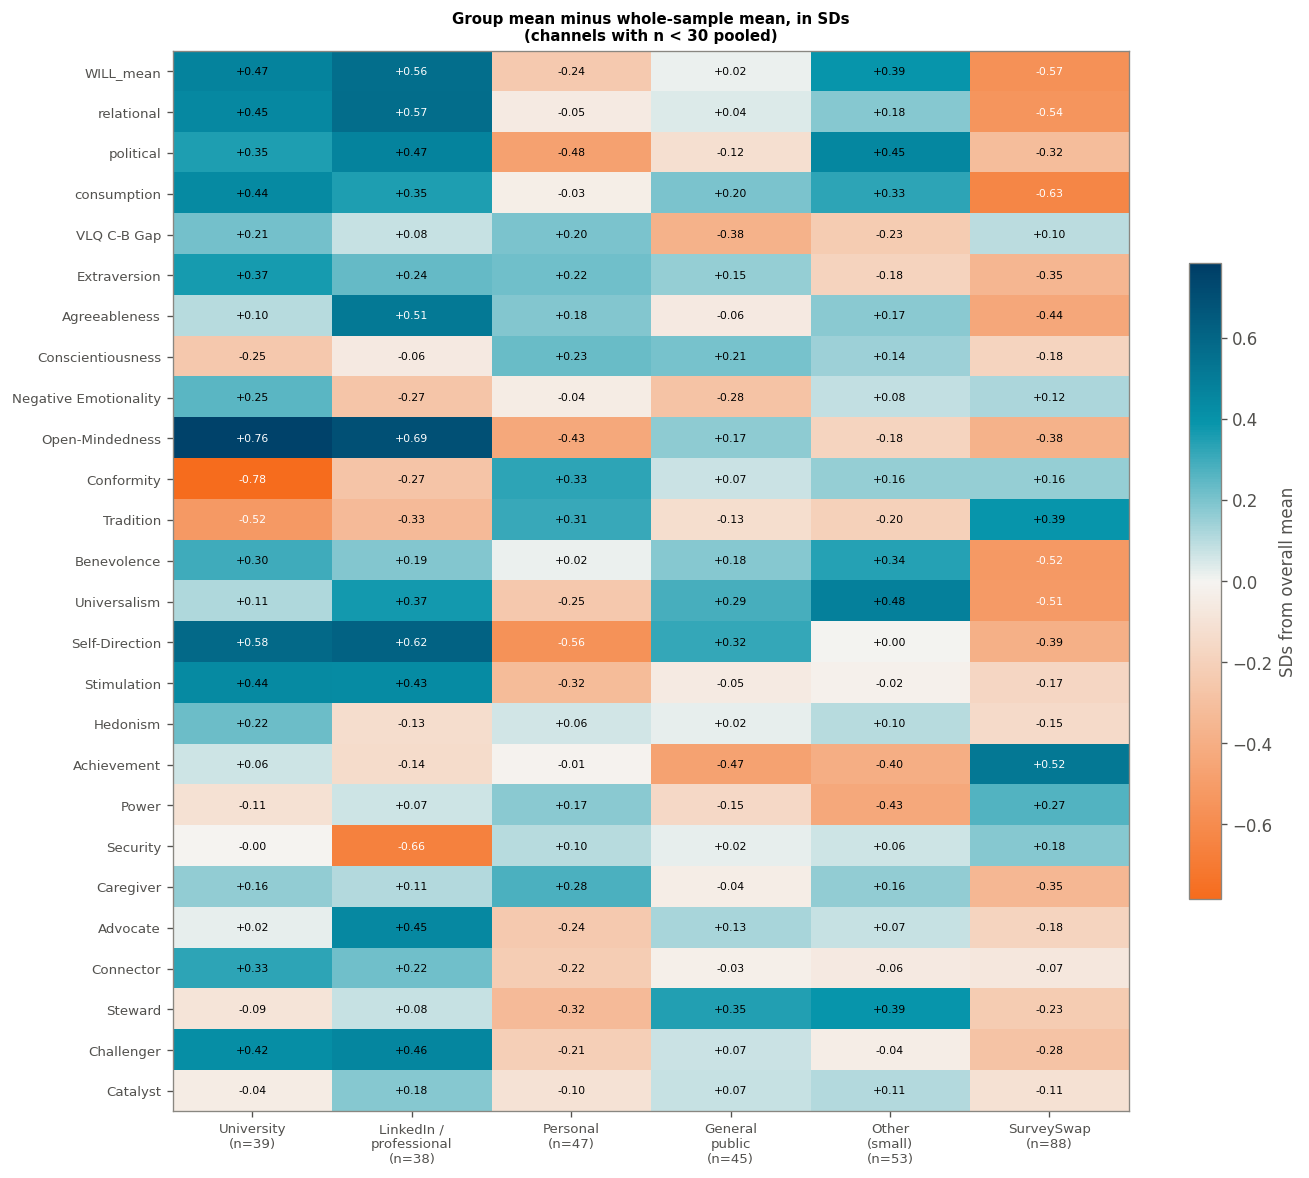

In [61]:
heat_vars = ['WILL_mean'] + comp_cols + ['VLQ C-B Gap'] + traits + archetypes
# Channels in reporting order rather than by size
groups = ['A', 'B', 'C', 'D', 'Other (small channels)', 'S']

# Each cell: how many SDs the channel's average sits above or below the sample average
matrix = np.array([
    [(csr.loc[csr['source_group'] == g, var].mean() - csr[var].mean()) / csr[var].std()
     for g in groups]
    for var in heat_vars
])

lim = max(0.2, np.abs(matrix).max())

fig, ax = plt.subplots(figsize=(1.6 * len(groups) + 2, 0.32 * len(heat_vars) + 1.6))
im = ax.imshow(matrix, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect='auto')

ax.set_xticks(range(len(groups)))
CHANNEL_LABELS = {'A': 'University', 'B': 'LinkedIn /\nprofessional', 'C': 'Personal',
                  'D': 'General\npublic', 'Other (small channels)': 'Other\n(small)',
                  'S': 'SurveySwap'}
ax.set_xticklabels([f"{CHANNEL_LABELS.get(g, g)}\n(n={(csr['source_group'] == g).sum()})"
                    for g in groups], fontsize=8)
ax.set_yticks(range(len(heat_vars)))
ax.set_yticklabels([v.replace('VALCEN ', '').replace('BFI ', '').replace('ARC ', '').replace('_score', '')
                    for v in heat_vars], fontsize=8)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, f'{matrix[i, j]:+.2f}', ha='center', va='center', fontsize=6.5,
                color='white' if abs(matrix[i, j]) > lim * 0.65 else 'black')

ax.set_title(f'Group mean minus whole-sample mean, in SDs\n(channels with n < {MIN_N} pooled)', fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.6, label='SDs from overall mean')
plt.tight_layout()
plt.show()

The channels sit on a gradient. SurveySwap respondents are at one end: below the sample mean on overall willingness (−0.57 SD) and on all three behavioural composites, and above it on Achievement (+0.52) and Tradition. The university and LinkedIn channels sit at the other end: higher willingness, markedly higher Open-Mindedness (+0.76 and +0.69) and Self-Direction, lower Conformity and Tradition. Most variables shift in the same direction between the two ends. Personal channels sit below average on political action and above on Conformity and Tradition. The general public link is the closest of the five to the sample mean across the grid.

The differences across channels are overwhelmingly differences in *level* rather than in relative profile (the component that the ipsatised analyses remove). The archetype rows vary less across channels than the willingness and trait rows above them.